# Virus × EVE's classification

In this work, we use RNA-seq data of mosquitoes, one of the most dangerous viral vectors on the planet and the organisms of interest in the RNAI lab team research to train a classification model capable of distinguish viral classified RNA sequences between real virus and EVEs _(Endogenous Viral Elements)_.

#### Context

__The EVEs Problem__

EVEs _(Endogenous viral elements)_ are sequences of viruses that integrate into their hosts's genome becoming part of it. It means that they are no longer circulating (no longer viruses).

Distinguishing these sequences from real virus sequences is a challenging task in the context of large-scale metagenomic data since, at the sequence level, EVEs possess all the characteristics of viral sequences.

So current research is filling reference databases with EVEs wrongly characterized as viral because of the lack of resources to make this differentiation. It leads to distortion of interpretations of biological phenomena and hinders future data mining and machine learning work focused on viruses using public data.

__Small RNA size profiles__

When a virus attacks a cell, it triggers the host's immune response. As a result of this interaction small RNA residues are generated describing very specific patterns in a way that they might be interpreted as evidence of the presence of the virus in the cell.

When aligning reads from a host RNA-seq library against contigs assembled with these same library reads we can compute the small RNA size profile of each assembled contig.

A contig small RNA size profile is the quantity of RNA-seq reads of each specified size aligned with the contig. These counts are differentiated between sense and antisense strand alignments.

For example, "X21" is the normalized quantity of 21-nucleotide RNA reads aligned with the sense viral classified contig strand and "X.21" is the analogous for the antisense strand.

#### Dataset

__Content__



The dataset is composed of contigs assembled with mosquitoes RNA-seq reads represented in structured way by small RNA size profile normalized attributes. These contigs were firstly classified as viral by sequence similarity based methods and then went over curation by RNAi lab specialists to detect EVEs erroneously set as viral.

Each entry represents a small RNA Size profile representation of a contig previously classified as "viral" by methods based on sequence similarity. In these methods, sequences are exhaustively compared against huge public catalogued sequence databases _(see [Genbank NCBI](https://www.ncbi.nlm.nih.gov/genbank/))_.

__Classification of interest for this work__

- `viral`: Represents sequences of real viruses;
- `eve`: Represents sequences of EVEs that were previously classified as viruses;

__Features__

Features are all already normalized (using Z-score) taking into account particularities of the RNA-seq libraries.

- __V1__: Unique contig identifier _(e.g., "RNPM71_Contig0_1.")_ composed by its source library ID _(e.g., "RNPM71")_ plus a corresponding code generated by the assembling software _(e.g., "Contig0_1")_;
- __lib__: RNA-seq library (sample) ID;
- __name__: Contig assembling software generated code;
- __class__: "viral" (real viral sequences) or "eve";
- __run__: Identifier of the batch and location in Europe or Brazil where the library was generated;
- __length__: Contig length (considered in the normalizations that generated the attributes);
- __seq_fw__: Sense strand sequence;
- __seq_bw__: Antisense strand sequence;

- __{X15..X35}__: Quantity of RNA-seq reads of each specified size aligned with sense strand of the contig.
- __{X.15..X.35}__: Quantity of RNA-seq reads of each specified size aligned with antisense strand of the contig.

- __{'dens15to18', 'dens20to22', 'dens25to29', 'ratiosi_pi', 'ratio_si', 'dens18to35'}__: These features are all combinations (sums or ratios) of the RNA size features whose values are considered to be biochemically meaningful;



#### Initialization

Parameters

In [3]:
random_state = 123
path_ds = '../../../asset/ds_virus-eves.tab'

Utils

In [4]:
format_percent = lambda var: f'{(100 * var):.2f}%'

## EDA

In [5]:
import pandas as pd

Import data

In [6]:
# virus_eves = pd.read_table(io.BytesIO(uploaded['Virus_and_EVEs.tab']), index_col='V1')
df_virus_eves = pd.read_table(path_ds)

In [5]:
df_virus_eves.head()

,V1,run,lib,class,name,X15,X16,X17,X18,X19,...,X.35,dens15to18,dens20to22,dens25to29,ratiosi_pi,ratio_si,dens18to35,length,seq_fw,seq_bw
0,RKPM26_Contig120_119,caratinga,RKPM26,viral,Contig120_119,0.234105,0.124664,-0.027890,0.176621,0.021856,...,-0.317521,1.846663,4.432182,0.073100,4.359081,0.700917,4.722421,481,CGGTGGCAACCCCCGCAAAACCCCGGTTCGTAGCTAGGATGCTTCC...,CCCGTGGTTCTGGGACACAACAGGCGCCGGTGACGACGAAACTTCT...
1,RKPM26_Contig1819_1818,caratinga,RKPM26,viral,Contig1819_1818,-0.072243,-0.062254,0.019318,0.064599,-0.004654,...,-0.308636,2.211863,5.080056,0.903501,4.176555,0.376193,5.382808,1051,GGTCCGGCCGCCGCTGAGGCGGCGGTGTACTTTATCGCCTTGGTGA...,AAGCTTGAGAAATCTATAAAGTATTAGATTATCAAGCGCCACACAA...
2,RKPM26_Contig1820_1819,caratinga,RKPM26,viral,Contig1820_1819,0.013123,0.004374,0.306210,0.188100,0.017498,...,-0.363078,0.536667,3.044934,-0.111031,3.155965,0.516932,3.465491,324,ACATGGTTTTGTGTTTTGCTATGGTGGGTGGAGGAGATTCCTCGCC...,ATCGCCACCATGGCCATGGAGTTGTCTGTGATGGTATTGAAGAGAC...
3,RKPM26_Contig1965_1964,caratinga,RKPM26,viral,Contig1965_1964,-0.028174,-0.017522,-0.034657,-0.015206,0.015824,...,-0.351899,0.770070,3.764117,0.300516,3.463602,0.031964,4.171750,1887,TTTTCTCGAGGATACTCTGCATCACCTACAAGTGACCGGTAACTCG...,AACCATGTTTTGATGGGATTGTGCTAGAACTGGCATTTAAAGCTTC...
4,RKPM26_Contig1967_1966,caratinga,RKPM26,viral,Contig1967_1966,0.235742,0.065989,0.309045,0.363057,0.204878,...,-0.346821,0.889817,3.127827,-0.824428,3.952256,0.470128,3.521716,340,ACGGAGGCCTCCGTTTCAGGCAAGTCGTTGGTTAATTTCATGTGTA...,CACTCGATGATAGTATCCGGATTCATGAACAAAATTGGAGGTGCAA...


In [6]:
df_virus_eves.shape

(2315, 56)

In [7]:
df_virus_eves.columns

Index(['V1', 'run', 'lib', 'class', 'name', 'X15', 'X16', 'X17', 'X18', 'X19',
       'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29',
       'X30', 'X31', 'X32', 'X33', 'X34', 'X35', 'X.15', 'X.16', 'X.17',
       'X.18', 'X.19', 'X.20', 'X.21', 'X.22', 'X.23', 'X.24', 'X.25', 'X.26',
       'X.27', 'X.28', 'X.29', 'X.30', 'X.31', 'X.32', 'X.33', 'X.34', 'X.35',
       'dens15to18', 'dens20to22', 'dens25to29', 'ratiosi_pi', 'ratio_si',
       'dens18to35', 'length', 'seq_fw', 'seq_bw'],
      dtype='object')

In [8]:
df_virus_eves.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2315 entries, 0 to 2314
Data columns (total 56 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   V1          2315 non-null   object 
 1   run         2315 non-null   object 
 2   lib         2315 non-null   object 
 3   class       2315 non-null   object 
 4   name        2315 non-null   object 
 5   X15         2315 non-null   float64
 6   X16         2315 non-null   float64
 7   X17         2315 non-null   float64
 8   X18         2315 non-null   float64
 9   X19         2315 non-null   float64
 10  X20         2315 non-null   float64
 11  X21         2315 non-null   float64
 12  X22         2315 non-null   float64
 13  X23         2315 non-null   float64
 14  X24         2315 non-null   float64
 15  X25         2315 non-null   float64
 16  X26         2315 non-null   float64
 17  X27         2315 non-null   float64
 18  X28         2315 non-null   float64
 19  X29         2315 non-null  

In [9]:
df_virus_eves.describe()

,X15,X16,X17,X18,X19,X20,X21,X22,X23,X24,...,X.33,X.34,X.35,dens15to18,dens20to22,dens25to29,ratiosi_pi,ratio_si,dens18to35,length
count,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,...,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000,2315.000000
mean,0.241999,0.105378,0.043433,0.018521,0.061851,0.206638,2.295576,0.218679,0.156373,0.289062,...,-0.448284,-0.454135,-0.458553,-1.225841,0.171738,0.804165,-0.634031,1.214379,2.565175,628.533045
std,1.132029,0.798526,0.671314,0.563787,0.531206,0.551741,2.262872,0.510741,0.532020,0.604860,...,0.141395,0.143538,0.146613,2.641036,2.979563,2.209316,3.402365,1.791983,1.888941,793.321471
min,-0.907421,-0.715439,-0.936360,-0.911555,-0.902333,-0.784033,-0.650760,-0.532806,-0.659179,-0.611708,...,-1.045614,-1.045614,-1.045614,-8.581201,-8.417853,-6.426265,-9.072803,0.000000,-1.590069,200.000000
25%,-0.319725,-0.317665,-0.319970,-0.312512,-0.277020,-0.211421,-0.023095,-0.097488,-0.157907,-0.128266,...,-0.531783,-0.539706,-0.548408,-3.027005,-2.110801,-0.633509,-3.451838,0.106009,1.188216,249.000000
50%,-0.184576,-0.193612,-0.190750,-0.178662,-0.105057,0.065398,2.070854,0.090598,0.003414,0.130437,...,-0.418813,-0.422734,-0.425913,-1.144076,0.455617,0.640034,-0.711087,0.532757,2.296617,358.000000
75%,0.230041,0.154120,0.119332,0.103929,0.220479,0.475388,4.528564,0.398941,0.314111,0.514076,...,-0.350740,-0.355591,-0.356489,0.422402,2.350529,2.105876,1.455370,1.382892,3.795794,614.500000
max,6.836349,6.418098,5.266740,3.865223,5.097639,4.296929,6.613526,6.441316,6.607433,6.068682,...,-0.057846,-0.102924,-0.128916,10.757198,8.307461,8.261057,10.571063,13.005098,9.925617,8702.000000


Check for missing values

In [10]:
df_virus_eves.isnull().sum().sum()
# df_virus_eves.isna().sum().sort_values(ascending=False)[0:54]

0

### Separate features (**X**) / Classes (**y**)

In [11]:
df_virus_eves.columns

Index(['V1', 'run', 'lib', 'class', 'name', 'X15', 'X16', 'X17', 'X18', 'X19',
       'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29',
       'X30', 'X31', 'X32', 'X33', 'X34', 'X35', 'X.15', 'X.16', 'X.17',
       'X.18', 'X.19', 'X.20', 'X.21', 'X.22', 'X.23', 'X.24', 'X.25', 'X.26',
       'X.27', 'X.28', 'X.29', 'X.30', 'X.31', 'X.32', 'X.33', 'X.34', 'X.35',
       'dens15to18', 'dens20to22', 'dens25to29', 'ratiosi_pi', 'ratio_si',
       'dens18to35', 'length', 'seq_fw', 'seq_bw'],
      dtype='object')

In [7]:
col_y_label = 'class'

cols_lib_id = ['V1', 'run', 'lib', 'name']
cols_sequence = ['length', 'seq_fw', 'seq_bw']

cols_X_aggregation = [
    'dens15to18', 'dens20to22', 'dens25to29', 'dens18to35', 'ratiosi_pi', 'ratio_si',
]

cols_X_size_profile_sense = [
    'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29', 'X30',
    'X31', 'X32', 'X33', 'X34', 'X35',
]
cols_X_size_profile_antisense = [
    'X.15', 'X.16', 'X.17', 'X.18', 'X.19', 'X.20', 'X.21', 'X.22', 'X.23', 'X.24', 'X.25', 'X.26', 'X.27', 'X.28', 'X.29', 'X.30',
    'X.31', 'X.32', 'X.33', 'X.34', 'X.35',
]

cols_X_size_profile = cols_X_size_profile_sense + cols_X_size_profile_antisense
cols_X = cols_X_size_profile + cols_X_aggregation

In [8]:
X = df_virus_eves[cols_X]
y = df_virus_eves[col_y_label]

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'X data types: {set(X.dtypes)}')

X.shape: (2315, 48)
y.shape: (2315,)
X data types: {dtype('float64')}


In [14]:
y.unique()

array(['viral', 'eve'], dtype=object)

In [10]:
label_viral = 'viral'
label_eve = 'eve'

color_viral = 'darkred'
color_eve = 'green'

label_color_map = {
    label_viral: color_viral,
    label_eve: color_eve,
}

### Classes balance

In [13]:
import matplotlib.pyplot as plt

In [11]:
df_viral = df_virus_eves[ df_virus_eves[col_y_label] == label_viral ]
df_viral.head()

,V1,run,lib,class,name,X15,X16,X17,X18,X19,...,X.35,dens15to18,dens20to22,dens25to29,ratiosi_pi,ratio_si,dens18to35,length,seq_fw,seq_bw
0,RKPM26_Contig120_119,caratinga,RKPM26,viral,Contig120_119,0.234105,0.124664,-0.027890,0.176621,0.021856,...,-0.317521,1.846663,4.432182,0.073100,4.359081,0.700917,4.722421,481,CGGTGGCAACCCCCGCAAAACCCCGGTTCGTAGCTAGGATGCTTCC...,CCCGTGGTTCTGGGACACAACAGGCGCCGGTGACGACGAAACTTCT...
1,RKPM26_Contig1819_1818,caratinga,RKPM26,viral,Contig1819_1818,-0.072243,-0.062254,0.019318,0.064599,-0.004654,...,-0.308636,2.211863,5.080056,0.903501,4.176555,0.376193,5.382808,1051,GGTCCGGCCGCCGCTGAGGCGGCGGTGTACTTTATCGCCTTGGTGA...,AAGCTTGAGAAATCTATAAAGTATTAGATTATCAAGCGCCACACAA...
2,RKPM26_Contig1820_1819,caratinga,RKPM26,viral,Contig1820_1819,0.013123,0.004374,0.306210,0.188100,0.017498,...,-0.363078,0.536667,3.044934,-0.111031,3.155965,0.516932,3.465491,324,ACATGGTTTTGTGTTTTGCTATGGTGGGTGGAGGAGATTCCTCGCC...,ATCGCCACCATGGCCATGGAGTTGTCTGTGATGGTATTGAAGAGAC...
3,RKPM26_Contig1965_1964,caratinga,RKPM26,viral,Contig1965_1964,-0.028174,-0.017522,-0.034657,-0.015206,0.015824,...,-0.351899,0.770070,3.764117,0.300516,3.463602,0.031964,4.171750,1887,TTTTCTCGAGGATACTCTGCATCACCTACAAGTGACCGGTAACTCG...,AACCATGTTTTGATGGGATTGTGCTAGAACTGGCATTTAAAGCTTC...
4,RKPM26_Contig1967_1966,caratinga,RKPM26,viral,Contig1967_1966,0.235742,0.065989,0.309045,0.363057,0.204878,...,-0.346821,0.889817,3.127827,-0.824428,3.952256,0.470128,3.521716,340,ACGGAGGCCTCCGTTTCAGGCAAGTCGTTGGTTAATTTCATGTGTA...,CACTCGATGATAGTATCCGGATTCATGAACAAAATTGGAGGTGCAA...


In [12]:
df_eve = df_virus_eves[ df_virus_eves[col_y_label] == label_eve ]
df_eve.head()

,V1,run,lib,class,name,X15,X16,X17,X18,X19,...,X.35,dens15to18,dens20to22,dens25to29,ratiosi_pi,ratio_si,dens18to35,length,seq_fw,seq_bw
1321,USUV_Contig19337_19336,Ajap_sandra,USUV,eve,Contig19337_19336,-0.443896,-0.443896,-0.443896,-0.399903,-0.267926,...,-0.443896,-5.385431,-0.965892,1.258425,-2.224317,2.211504,1.824997,418,TGCCTTCTTCCCTAAAACTGCTAGTCTTGCACCTAGCAACGATGTC...,AAACGAACCCAATTTACAGAGCAATAGATACGACTGCTAGTGAATT...
1322,USUV_Contig6449_6448,Ajap_sandra,USUV,eve,Contig6449_6448,-0.464588,-0.464588,-0.464588,-0.344694,-0.044960,...,-0.464588,-6.686501,-1.599038,0.279284,-1.878321,4.000000,0.860394,206,TATATGACGCTGAAAGCCTGGACAAGATGAAAAACATGATCTATGA...,CCAGTTTGACCATGATATGAACTTGGACCAGTATCTGTTGAAAACG...
1323,USUV_Contig7578_7577,Ajap_sandra,USUV,eve,Contig7578_7577,-0.438586,-0.438586,-0.438586,-0.376819,0.127608,...,-0.438586,-5.117458,-0.238312,2.521237,-2.759549,4.147899,3.075892,243,GTCCAGCTTTTACCTTCAGTACGTTCATCTTAACATTCTTCTCAGG...,ATACAAAAATATAAGCGATGGAAACAACTCAGGCAACAGGTAGCGG...
1324,USUV_Contig6739_6738,Ajap_sandra,USUV,eve,Contig6739_6738,-0.413033,-0.413033,-0.413033,-0.413033,-0.217707,...,-0.413033,0.000000,-1.248576,-1.949016,0.700440,0.123382,-0.391021,278,ACTGAAAAAAAACTTATACTAAACATACAGGTTAAACTAACTACAA...,TAGTGAATGTAAGTATTTAAGCTGTTTACCAGTTATCTGGTATGCA...
1325,USUV_Contig19383_19382,Ajap_sandra,USUV,eve,Contig19383_19382,-0.306092,-0.306092,-0.306092,-0.293508,-0.218000,...,-0.306092,-6.921246,-2.921246,1.797801,-4.719047,0.660514,1.950967,606,TTTTTTTTTCTTTTTACATTTCTTCCCACCTAGCTGCTTGATTAAA...,GCAATAATTATCAGCTAGGCAACAGCGCAGATTGTATGAAGTTGTG...


Viral Class:	1321 (57.06%)
EVE Class:	994 (42.94%)


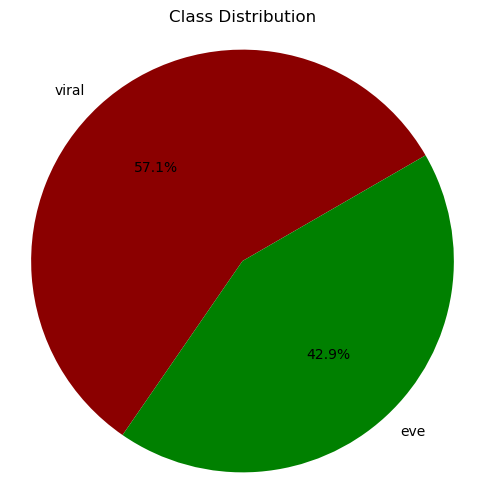

In [14]:
# Get classes distribution
class_value_counts = y.value_counts()
n_viral = class_value_counts[label_viral]
n_eve = class_value_counts[label_eve]

print(f'Viral Class:\t{n_viral} ({format_percent(n_viral / len(y))})')
print(f'EVE Class:\t{n_eve} ({format_percent(n_eve / len(y))})')

# Create a pie chart
class_counts = [class_value_counts[label_viral], class_value_counts[label_eve]]

plt.figure(figsize=(6, 6))
plt.pie(class_counts, labels=[label_viral, label_eve], autopct='%1.1f%%', startangle=30, colors=[color_viral, color_eve])
plt.title('Class Distribution')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()


### Feature values distribution

In [20]:
''' 
    # TODO: 2023-10-05 - ADD Description
'''

' \n    # TODO: 2023-10-05 - ADD Description\n'

In [21]:
import math

In [22]:
def plot_hist_grid(cols: list, hist_per_row=4) -> None:

    # Define number of rows / columns
    num_rows = math.ceil(len(cols) / hist_per_row)
    num_cols = hist_per_row

    # Create a grid of subplots
    unit_height = 3
    unit_width = 3
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * unit_width, num_rows * unit_height))

    # Plot histograms for each column
    axes = axes.flatten()
    for i, col in enumerate(cols):
        ax = axes[i]
        
        # Different each class setting custom colors
        for label, color in label_color_map.items():
            subset = df_virus_eves[df_virus_eves[col_y_label] == label]
            subset[col].plot.hist(alpha=0.5, ax=ax, color=color, label=label)

        ax.legend()
        ax.set_xlabel(col, fontsize=15)
        ax.grid(linestyle="--")

    plt.tight_layout()
    plt.show()

Size profile features (Sense strand)

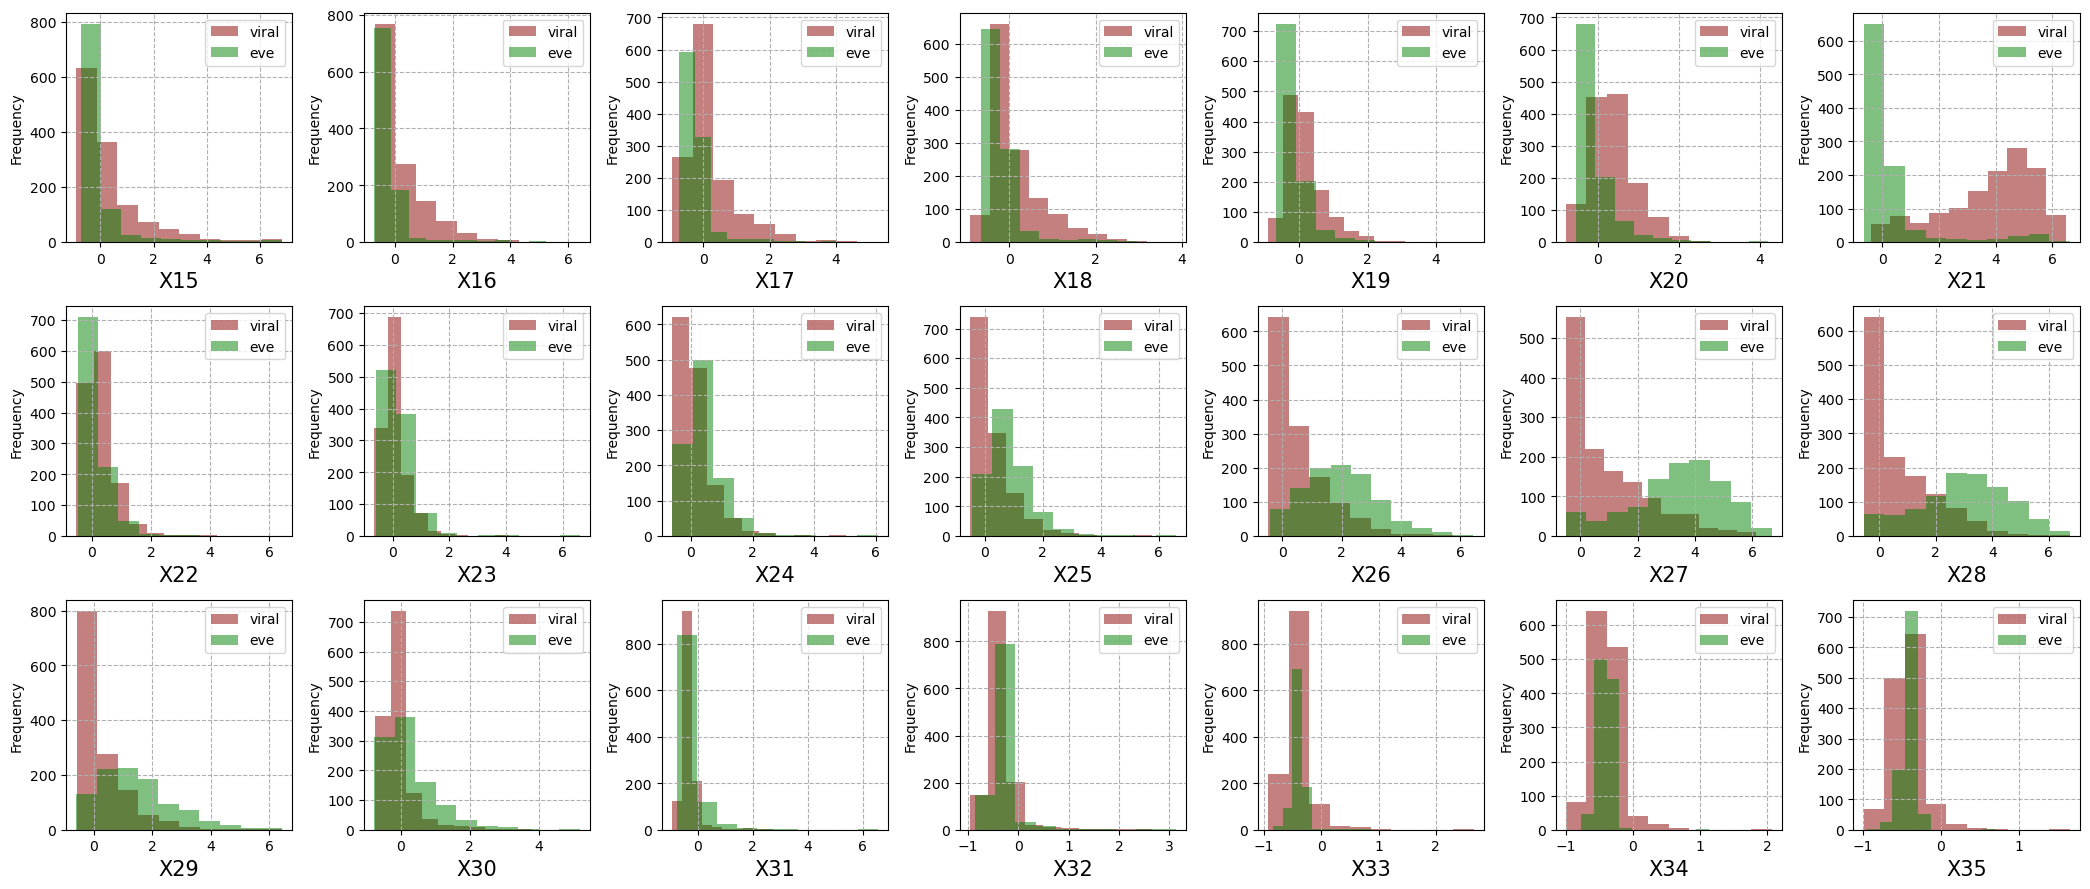

In [23]:
# X[cols_X_size_profile_sense].hist(figsize=(25, 10), layout=(3, 7))
# plt.show()
plot_hist_grid(cols=cols_X_size_profile_sense, hist_per_row=7)

Size profile (Antisense strand)

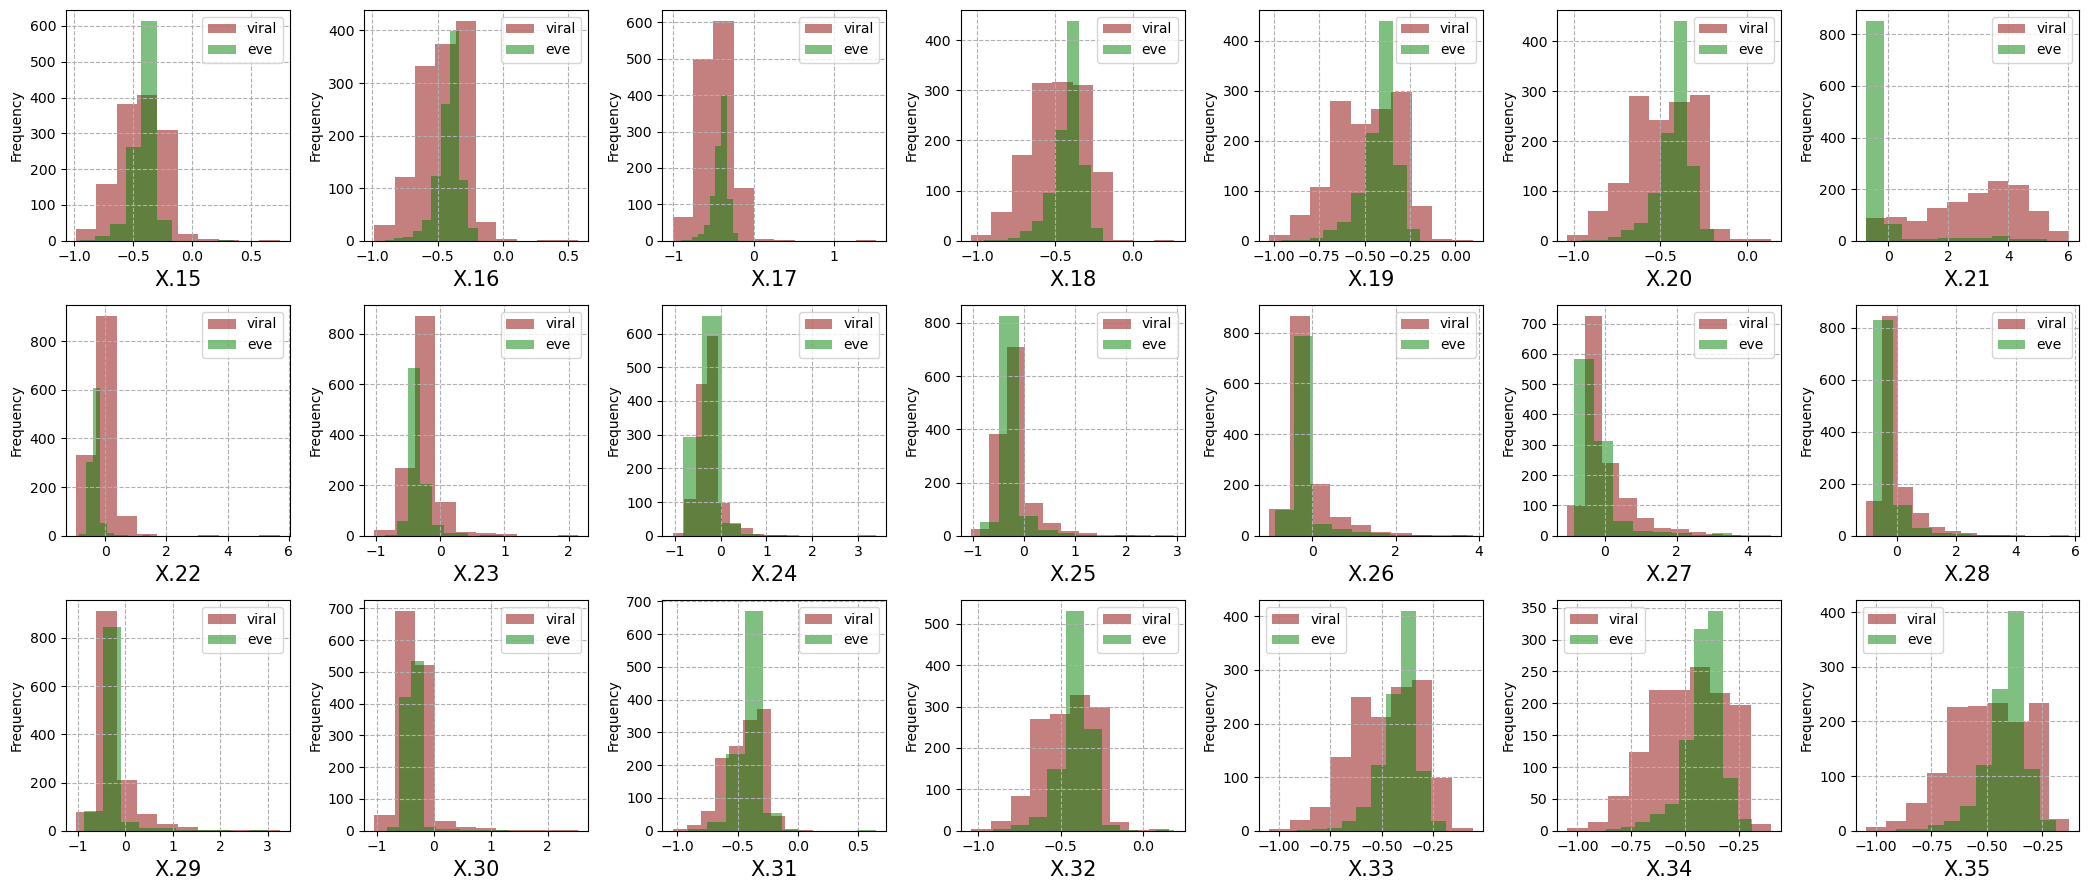

In [24]:
# X[cols_X_size_profile_antisense].hist(figsize=(25, 10), layout=(3, 7))
# plt.show()
plot_hist_grid(cols=cols_X_size_profile_antisense, hist_per_row=7)

Aggregated features

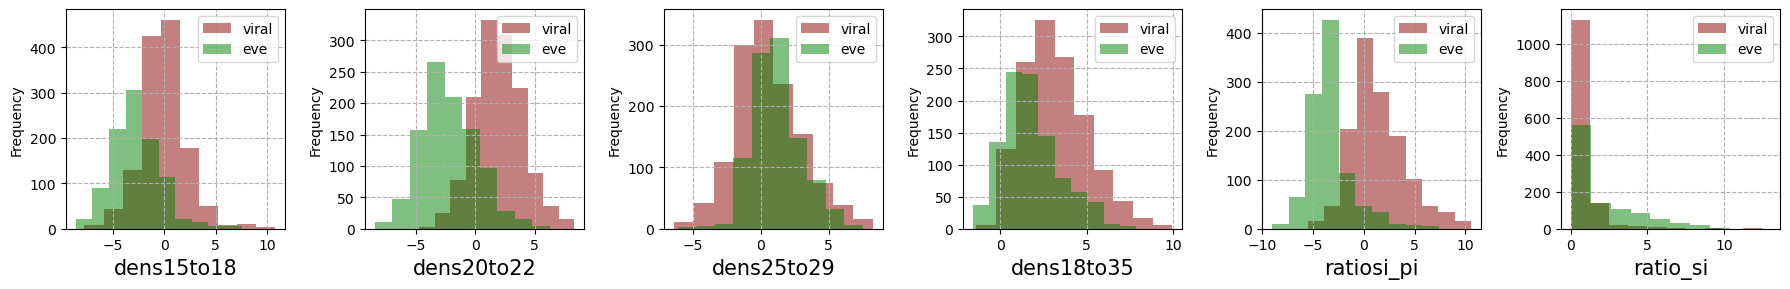

In [25]:
# X[cols_X_aggregation].hist(figsize=(25, 10), layout=(3, 7))
# plt.show()
plot_hist_grid(cols=cols_X_aggregation, hist_per_row=6)

### Features correlation

In [26]:
''' 
    # TODO: 2023-10-05 - ADD Description
'''

' \n    # TODO: 2023-10-05 - ADD Description\n'

In [27]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [28]:
def pair_plot(cols_subset: list) -> None:
    sns.set_theme(style="whitegrid", color_codes=True);
    palette = sns.xkcd_palette(['red', 'light blue'])
    df = df_virus_eves[cols_subset + [col_y_label]]
    sns.pairplot(df, hue=col_y_label, diag_kind='kde', palette=palette, plot_kws=dict(alpha=.5), diag_kws=dict(fill=True))

def plot_corr_heatmap(df: pd.DataFrame, title='Correlation Matrix', figsize=(18, 14)) -> None:
    plt.figure(figsize=figsize)
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title(title)
    plt.show()


All together

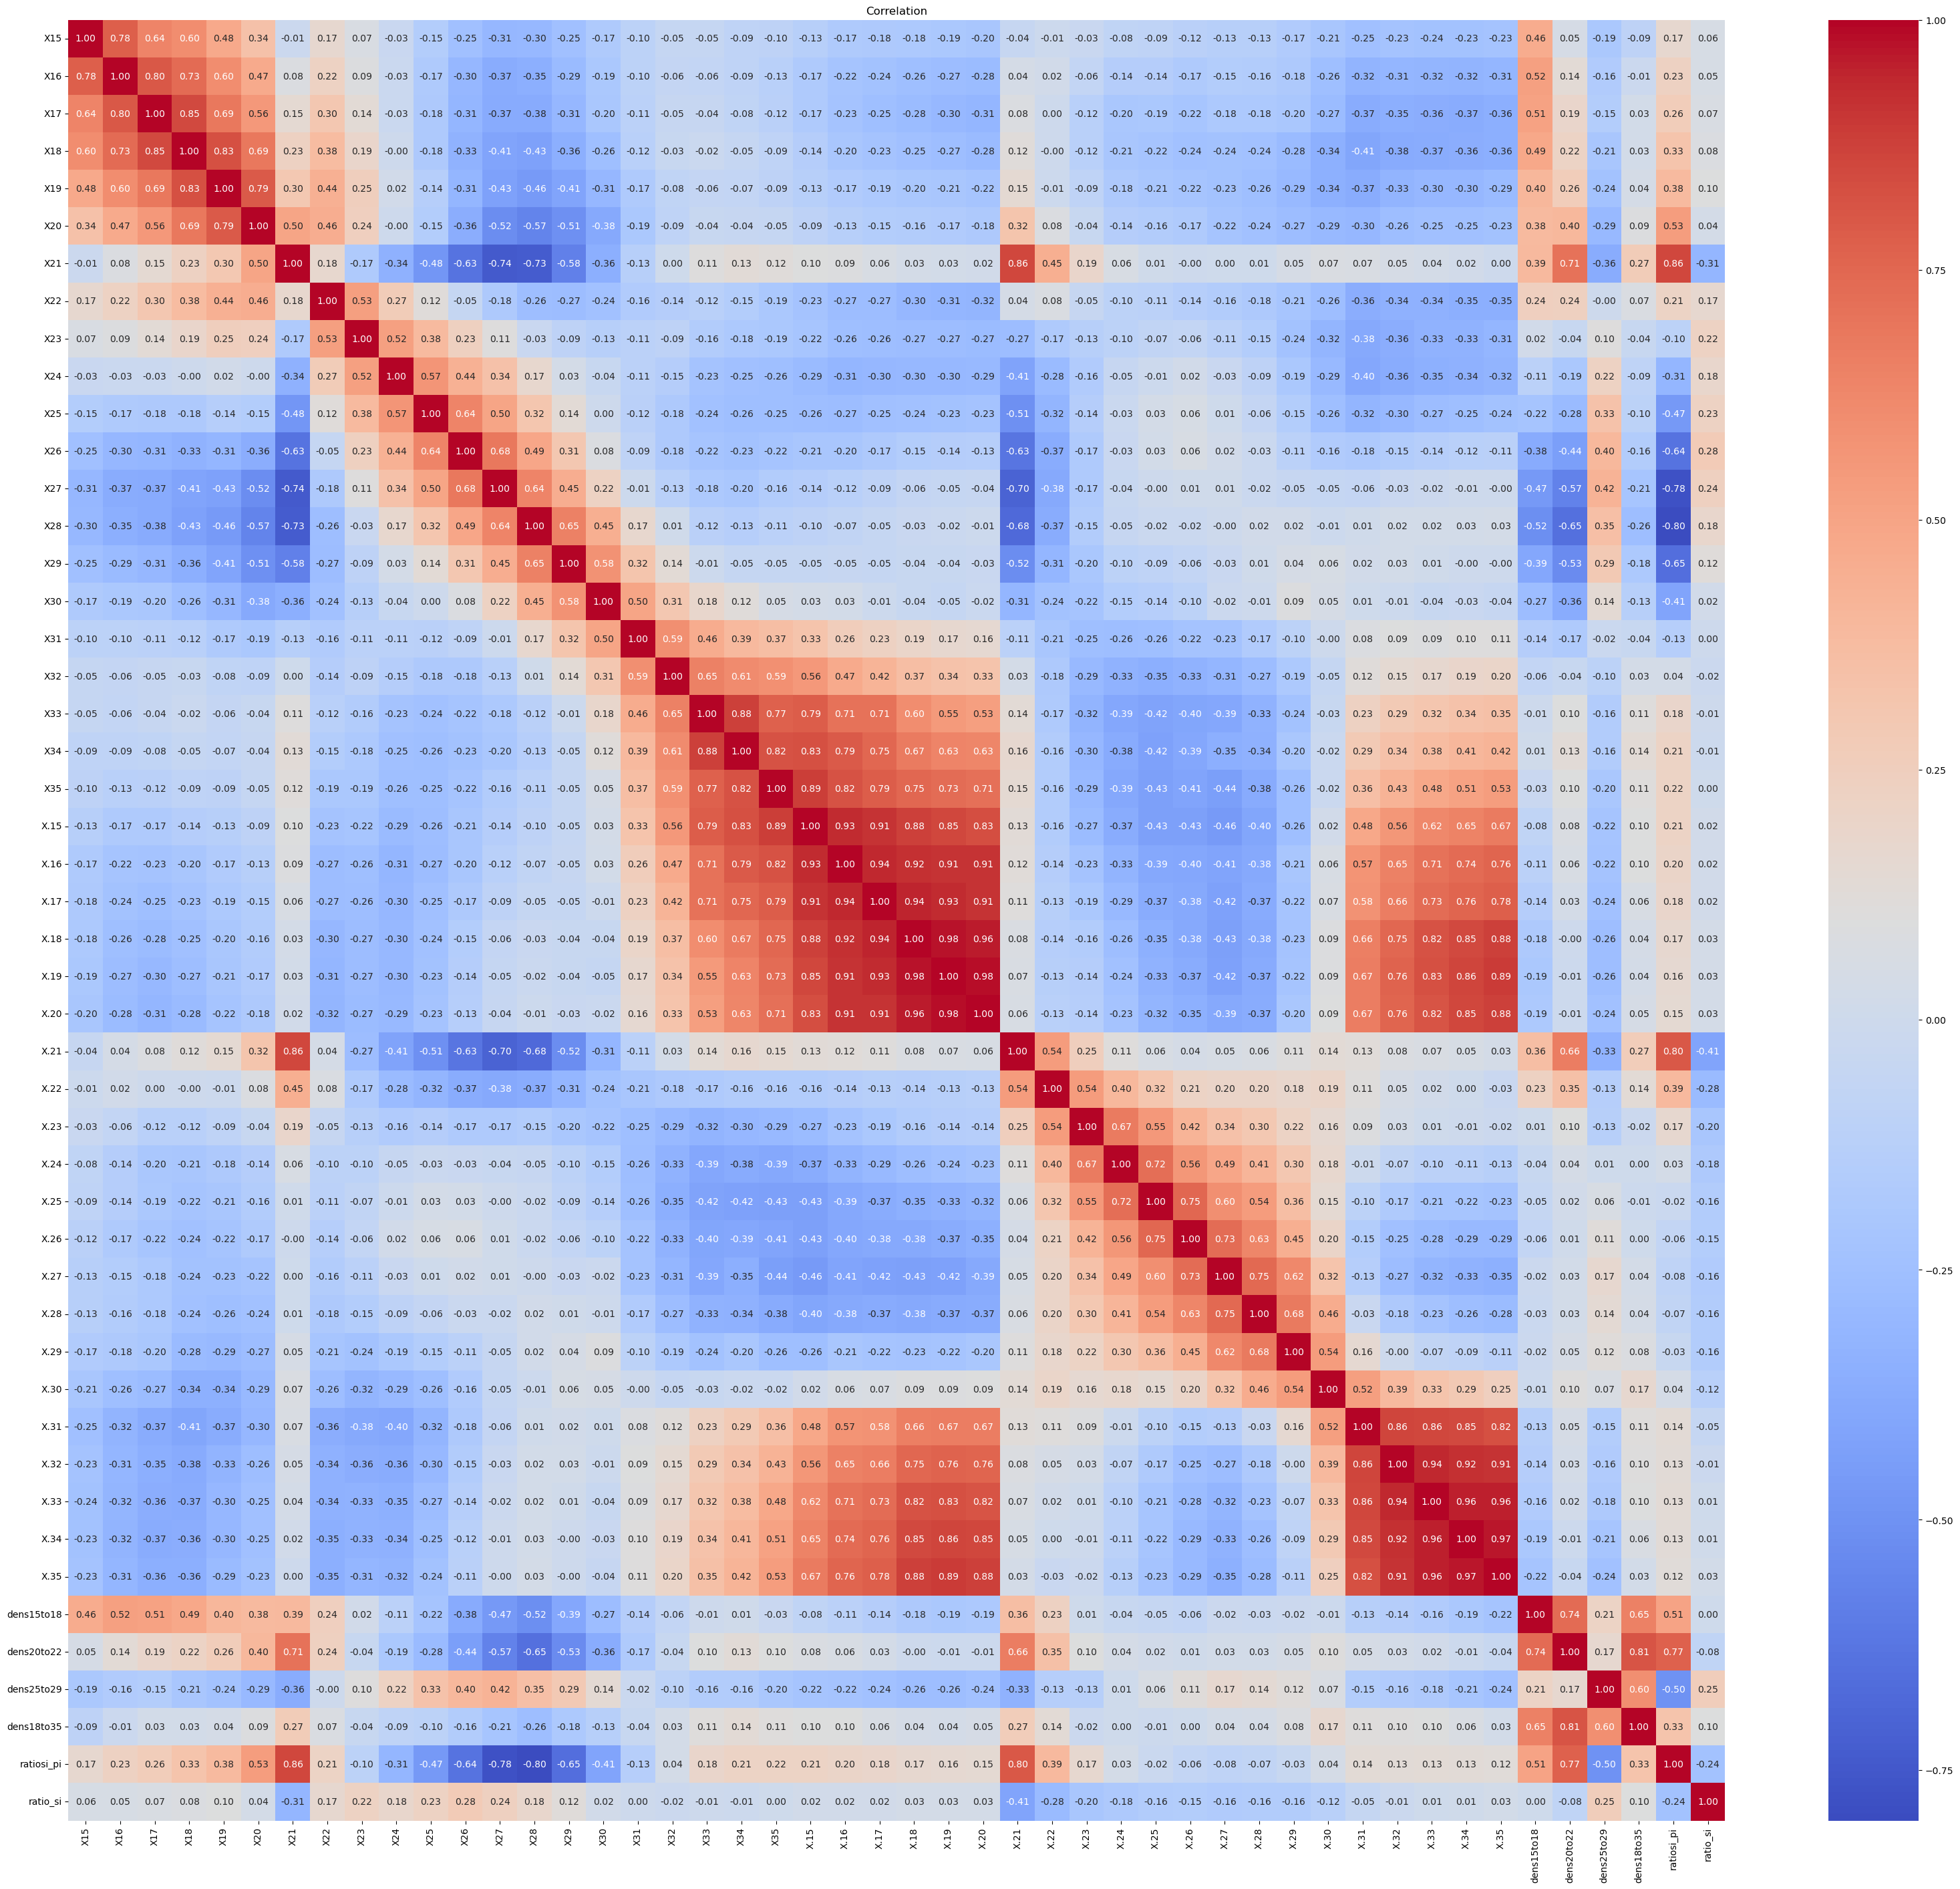

In [29]:
plot_corr_heatmap(df=X, title='Correlation', figsize=(40, 35))

 Size Profile (sense strand)

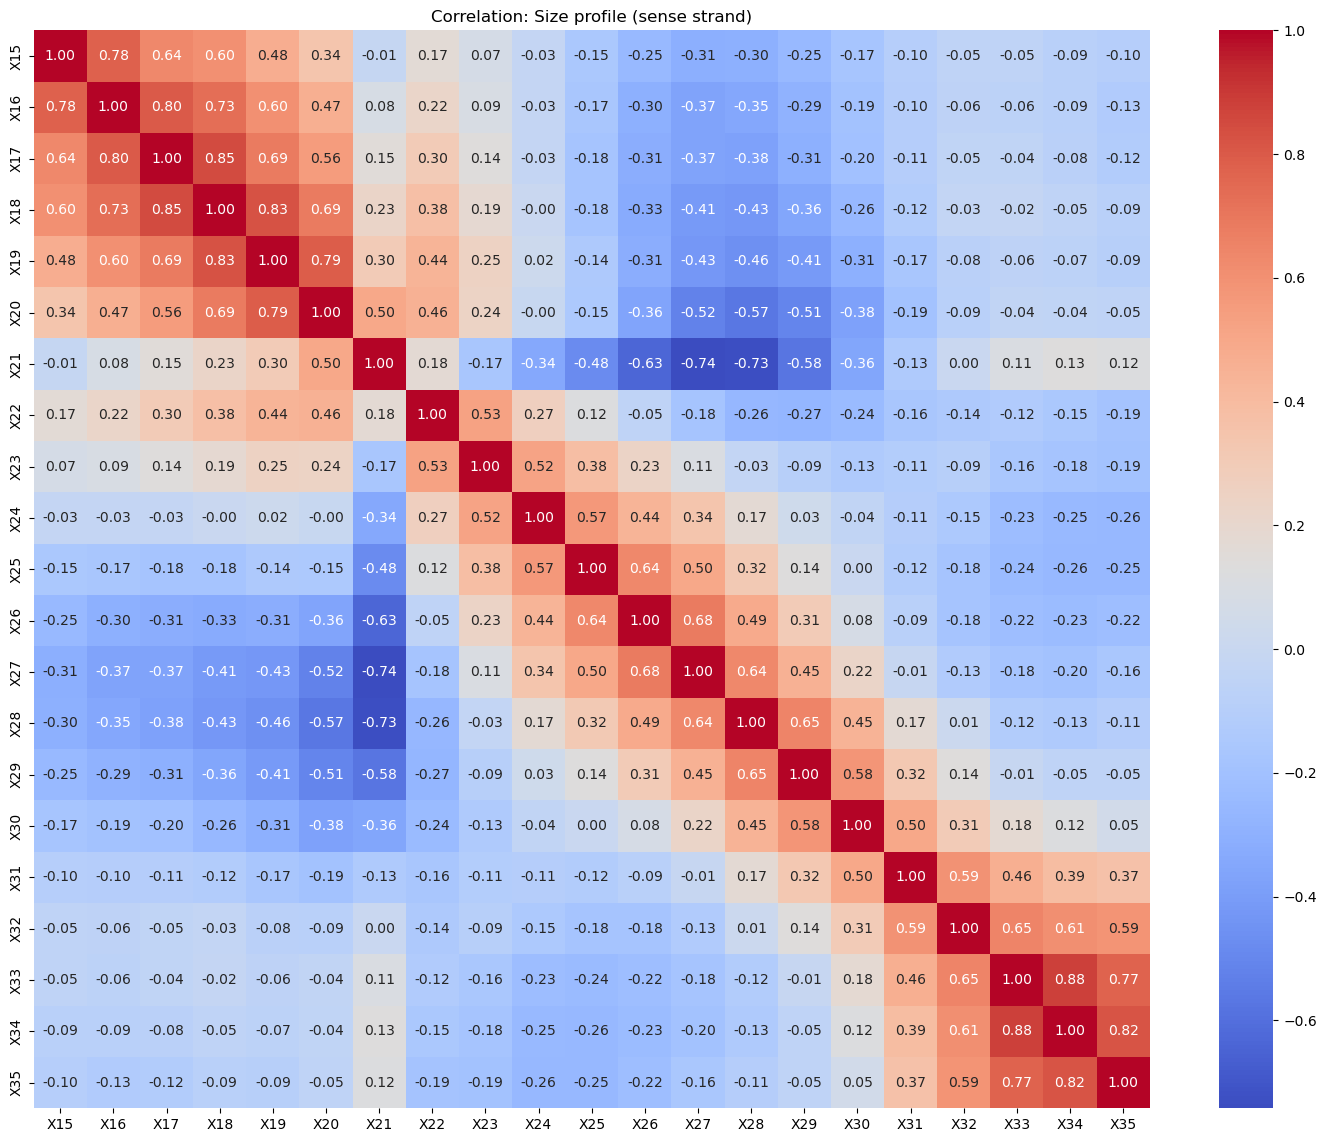

In [30]:
plot_corr_heatmap(df=X[cols_X_size_profile_sense], title='Correlation: Size profile (sense strand)')

 Size Profile (antisense strand)

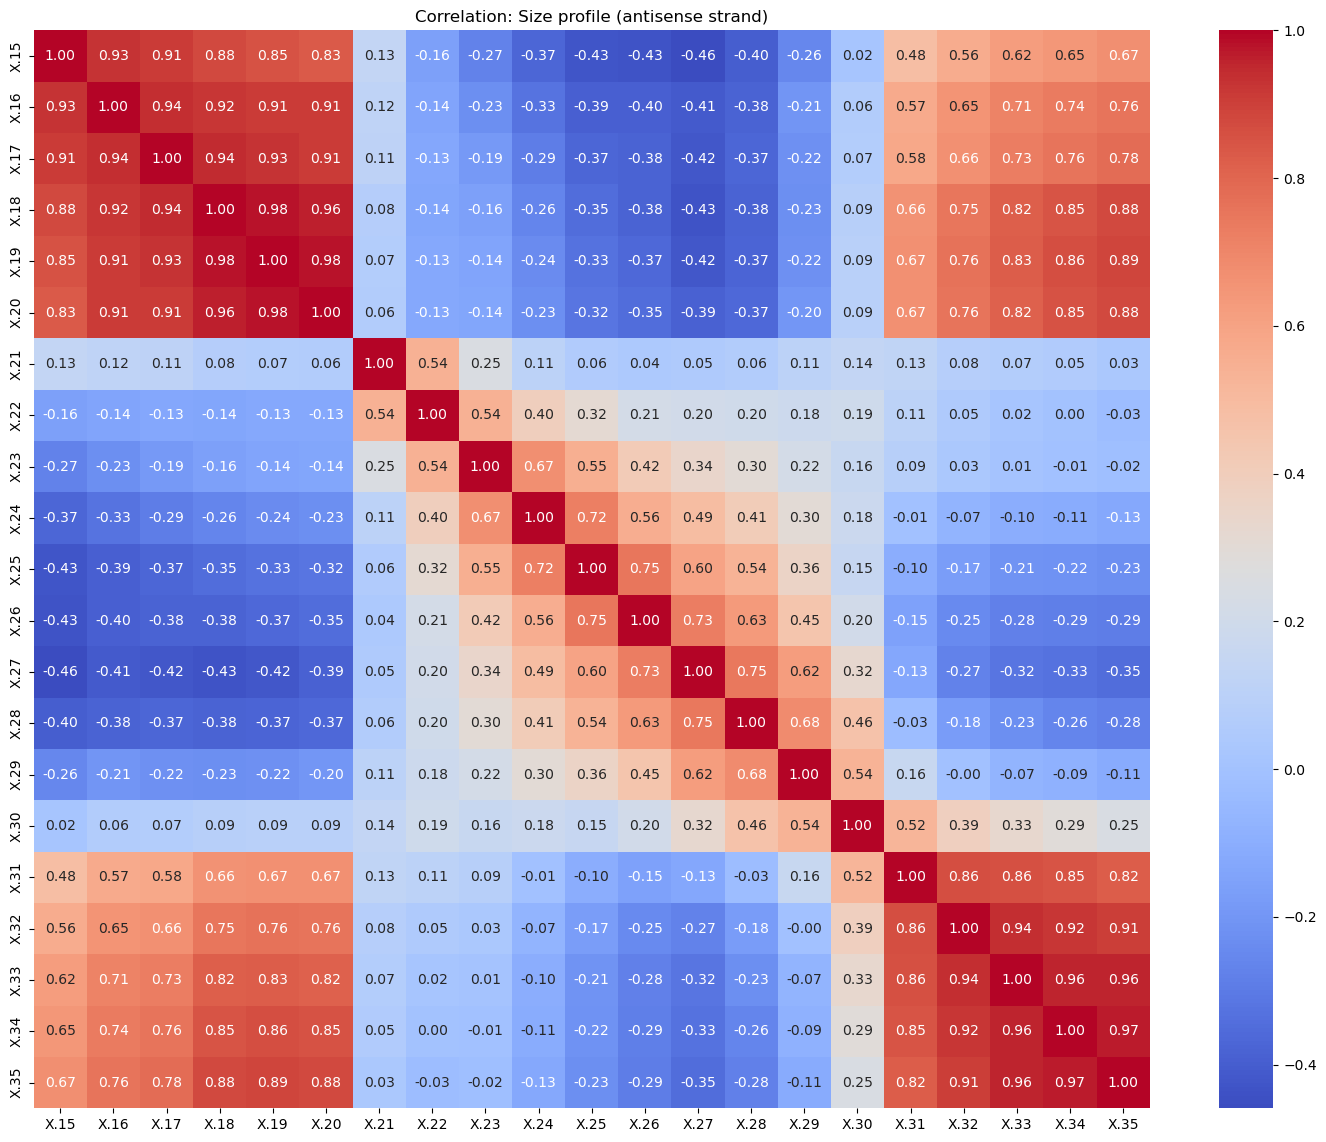

In [31]:
plot_corr_heatmap(df=X[cols_X_size_profile_antisense], title='Correlation: Size profile (antisense strand)')

Aggregated features

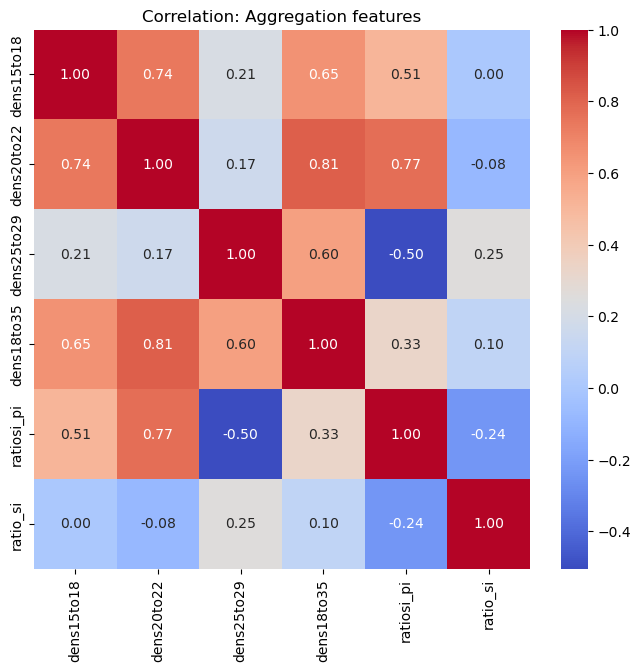

In [32]:
plot_corr_heatmap(df=X[cols_X_aggregation], title='Correlation: Aggregation features', figsize=(8, 7))

/home/hjcosta/miniconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


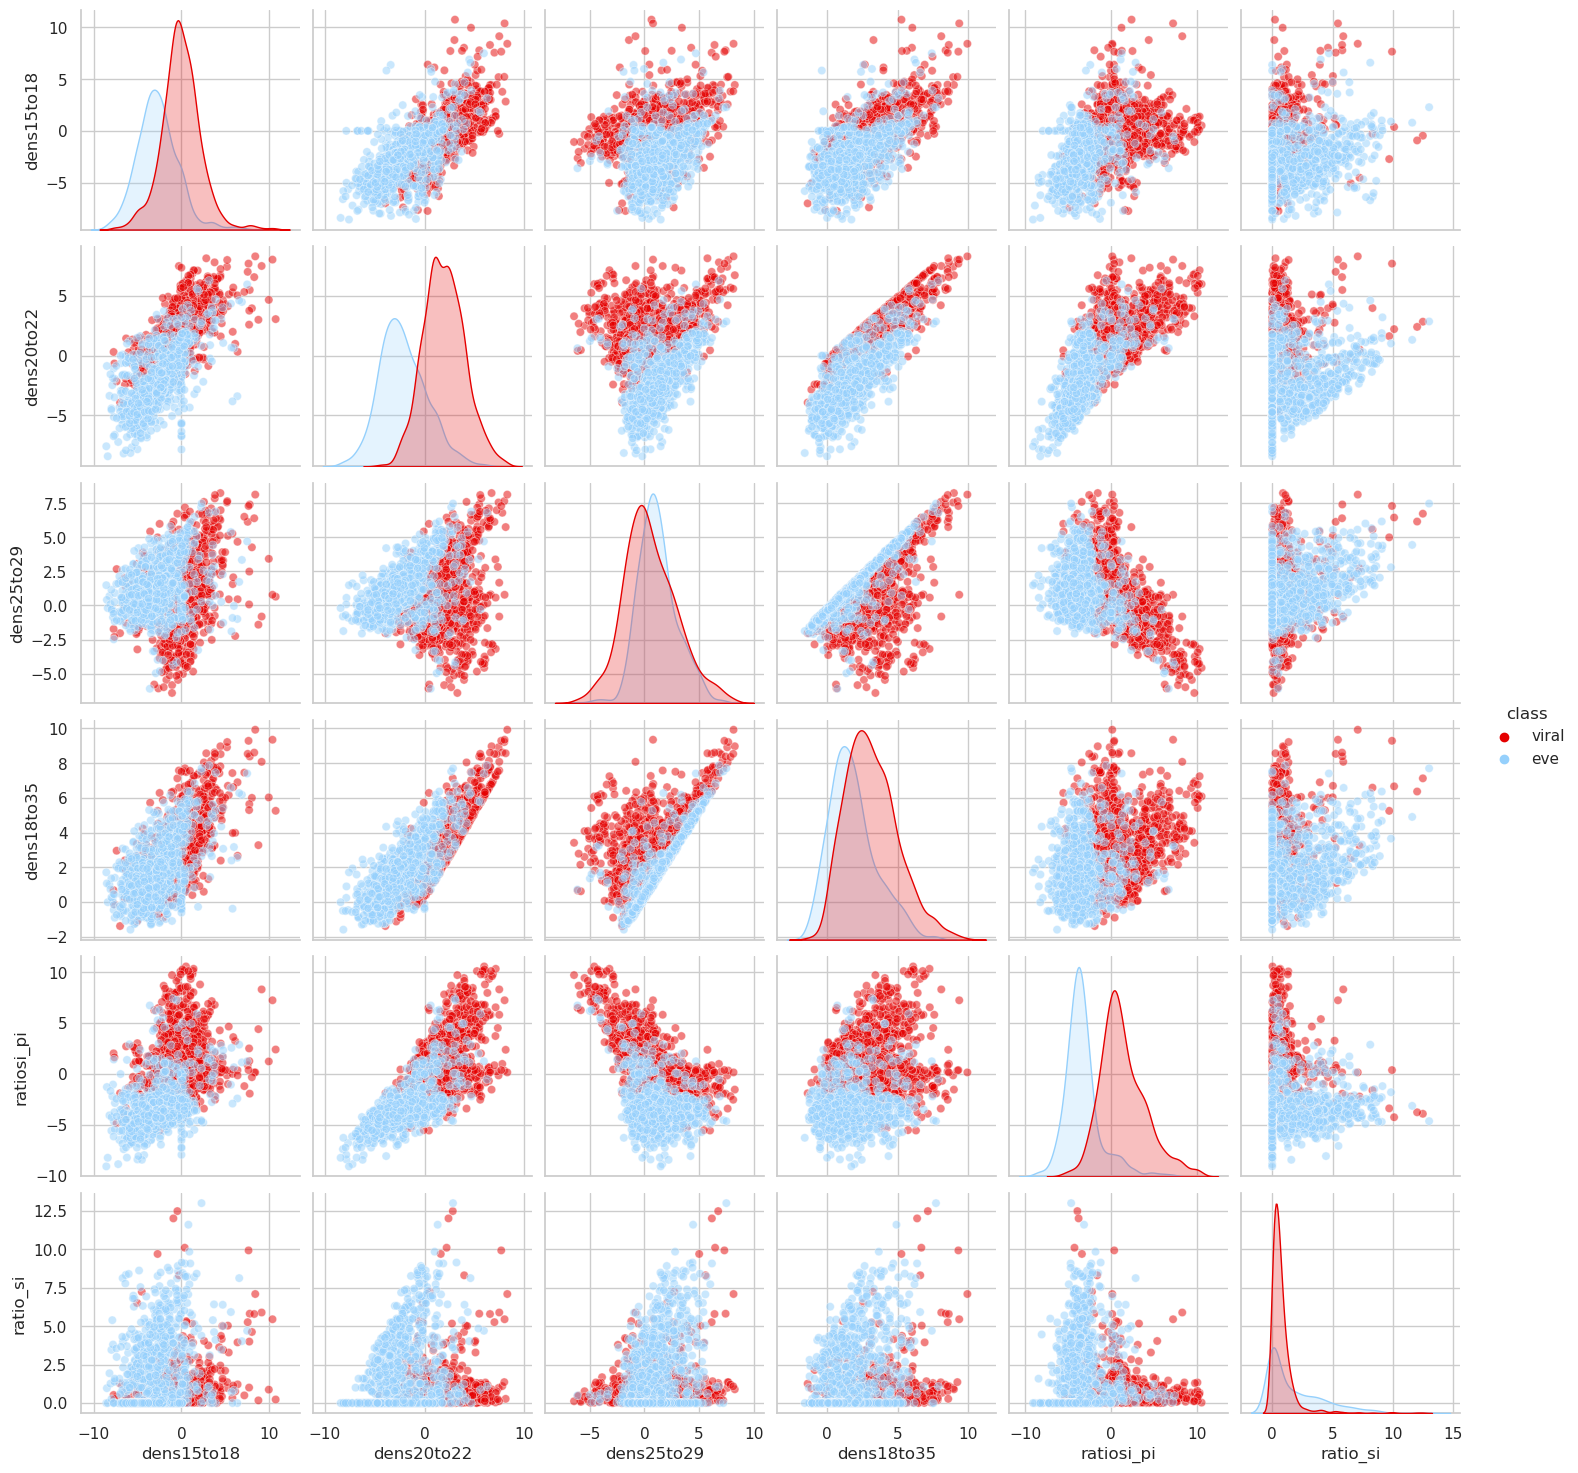

In [33]:
pair_plot(cols_subset=cols_X_aggregation)

### Spacial distribution of data representations

In [34]:
''' 
    # TODO: 2023-10-05 - ADD Description
'''

' \n    # TODO: 2023-10-05 - ADD Description\n'

#### t-SNE _(t-Distributed Stochastic Neighbor Embedding)_

In [35]:
from sklearn.manifold import TSNE
import seaborn as sns
import numpy as np

02 Components

In [36]:
tsne2 = TSNE(n_components=2, verbose=1, random_state=random_state)
tsne2_proj = tsne2.fit_transform(X)
tsne2.get_params()

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2315 samples in 0.001s...
[t-SNE] Computed neighbors for 2315 samples in 0.152s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2315
[t-SNE] Computed conditional probabilities for sample 2000 / 2315
[t-SNE] Computed conditional probabilities for sample 2315 / 2315
[t-SNE] Mean sigma: 1.530579


[t-SNE] KL divergence after 250 iterations with early exaggeration: 69.980499
[t-SNE] KL divergence after 1000 iterations: 1.082709


{'angle': 0.5,
 'early_exaggeration': 12.0,
 'init': 'pca',
 'learning_rate': 'auto',
 'method': 'barnes_hut',
 'metric': 'euclidean',
 'metric_params': None,
 'min_grad_norm': 1e-07,
 'n_components': 2,
 'n_iter': 1000,
 'n_iter_without_progress': 300,
 'n_jobs': None,
 'perplexity': 30.0,
 'random_state': 123,
 'square_distances': 'deprecated',
 'verbose': 1}

In [37]:
print(f't-SNE shape: {tsne2_proj.shape}')

t-SNE shape: (2315, 2)


[Text(0.5, 1.0, 't-SNE projection (viral × EVEs sequences)')]

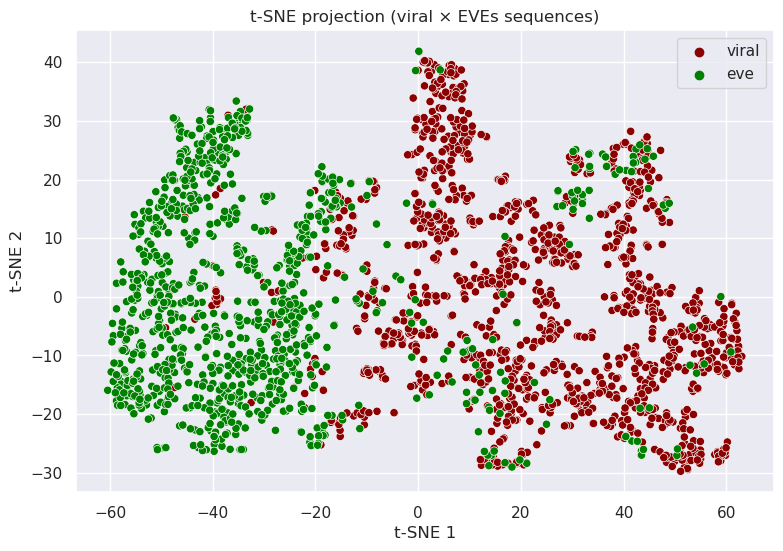

In [38]:
tsne2_aux_X = pd.DataFrame({
    'y': y,
    't-SNE 1': tsne2_proj[:,0],
    't-SNE 2': tsne2_proj[:,1],
})

sns.set(rc={ 'figure.figsize': (9, 6) })

plot = sns.scatterplot(
    x="t-SNE 1", y="t-SNE 2", data=tsne2_aux_X,
    hue=tsne2_aux_X.y.tolist(), palette=[color_viral, color_eve]

)

plot.set(title="t-SNE projection (viral × EVEs sequences)")

03 Components

In [39]:
tsne3 = TSNE(n_components=3, verbose=1, random_state=random_state)
tsne3_proj = tsne3.fit_transform(X)
tsne3.get_params()

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2315 samples in 0.001s...
[t-SNE] Computed neighbors for 2315 samples in 0.127s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2315
[t-SNE] Computed conditional probabilities for sample 2000 / 2315
[t-SNE] Computed conditional probabilities for sample 2315 / 2315
[t-SNE] Mean sigma: 1.530579


[t-SNE] KL divergence after 250 iterations with early exaggeration: 70.152863
[t-SNE] KL divergence after 1000 iterations: 0.915248


{'angle': 0.5,
 'early_exaggeration': 12.0,
 'init': 'pca',
 'learning_rate': 'auto',
 'method': 'barnes_hut',
 'metric': 'euclidean',
 'metric_params': None,
 'min_grad_norm': 1e-07,
 'n_components': 3,
 'n_iter': 1000,
 'n_iter_without_progress': 300,
 'n_jobs': None,
 'perplexity': 30.0,
 'random_state': 123,
 'square_distances': 'deprecated',
 'verbose': 1}

In [40]:
print(f't-SNE shape: {tsne3_proj.shape}')

t-SNE shape: (2315, 3)


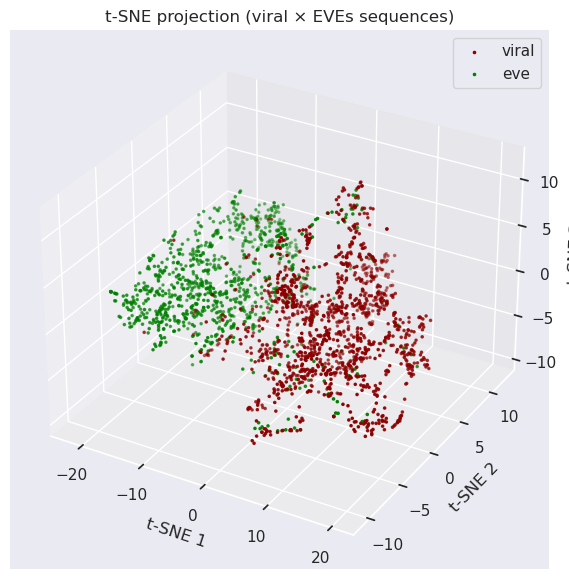

In [41]:

# Prepare data to plot
aux = np.concatenate( (np.zeros(n_viral), np.ones(n_eve)) )
tsne3_proj_viral = tsne3_proj[aux == 0, :]
tsne3_proj_eve = tsne3_proj[aux == 1, :]

# Create 3D scatter plot
fig = plt.figure(figsize=(20, 7))
ax = fig.add_subplot(111, projection='3d')

scatter_viral = ax.scatter(
    tsne3_proj_viral[:, 0], tsne3_proj_viral[:, 1], tsne3_proj_viral[:, 2],
    marker='.', s=10, c=color_viral, label=label_viral
)
scatter_eve = ax.scatter(
    tsne3_proj_eve[:, 0], tsne3_proj_eve[:, 1], tsne3_proj_eve[:, 2],
    marker='.', s=10, c=color_eve, label=label_eve
)

ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')
ax.set_zlabel('t-SNE 3')
ax.legend(handles=[scatter_viral, scatter_eve])

plt.title('t-SNE projection (viral × EVEs sequences)')
plt.show()


 #### PCA _(Principal Component Analysis)_

In [42]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

02 principal components

In [43]:
pca2 = PCA(n_components=2, random_state=random_state)
pca2_proj = pca2.fit_transform(X)

In [44]:
pca2_variances = [format_percent(var) for var in pca2.explained_variance_ratio_]
pca2_variance_total = format_percent(sum(pca2.explained_variance_ratio_))

print(f'PCA shape: {pca2_proj.shape}')
print(f'PCA variance (%): {pca2_variance_total} ({pca2_variances[0]} + {pca2_variances[1]})')

PCA shape: (2315, 2)
PCA variance (%): 72.28% (54.26% + 18.01%)


[Text(0.5, 1.0, 'PCA projection (viral × EVEs sequences)')]

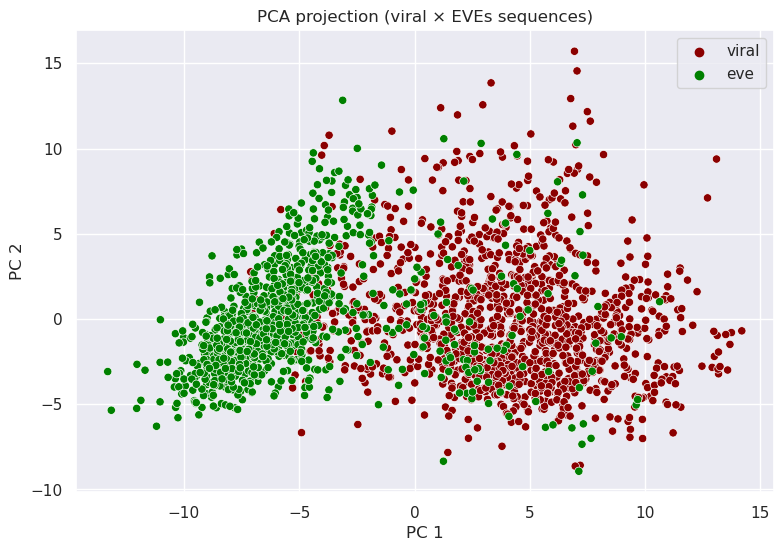

In [45]:
pca2_aux_df = pd.DataFrame({
    'y': y,
    'PC 1': pca2_proj[:, 0],
    'PC 2': pca2_proj[:, 1],
})

sns.set(rc={ 'figure.figsize': (9, 6) })

plot = sns.scatterplot(
    x="PC 1", y="PC 2", data=pca2_aux_df,
    hue=pca2_aux_df.y.tolist(), palette=[color_viral, color_eve]
)

plot.set(title='PCA projection (viral × EVEs sequences)')

03 Principal Components

In [46]:
pca3_aux_X = np.vstack( (df_viral[cols_X].values, df_eve[cols_X].values))
pca3 = PCA(n_components=3, random_state=random_state)
pca3_proj = pca3.fit_transform(pca3_aux_X)

In [47]:
pca3_variances = [format_percent(var) for var in pca3.explained_variance_ratio_]
pca3_variance_total = format_percent(sum(pca3.explained_variance_ratio_))

print(f'PCA shape: {pca3_proj.shape}')
print(f'PCA variance (%): {pca3_variance_total} ({pca3_variances[0]} + {pca3_variances[1]} + {pca3_variances[2]})')

PCA shape: (2315, 3)
PCA variance (%): 79.70% (54.26% + 18.01% + 7.43%)


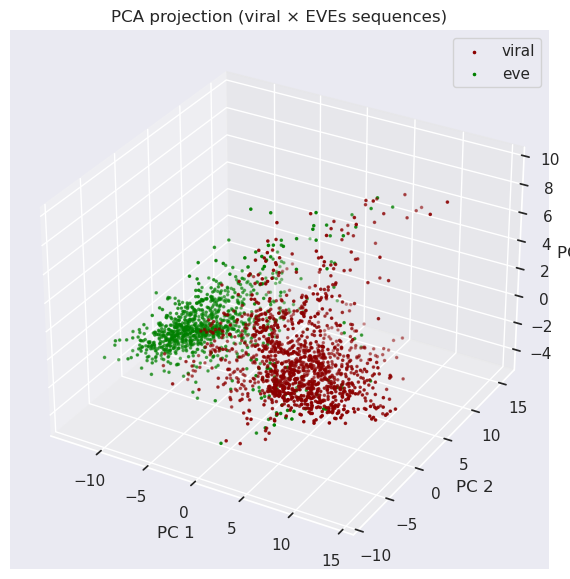

In [48]:

# Prepare data to plot
aux = np.concatenate( (np.zeros(n_viral), np.ones(n_eve)) )
pca3_proj_viral = pca3_proj[aux == 0, :]
pca3_proj_eve = pca3_proj[aux == 1, :]

# Create 3D scatter plot
fig = plt.figure(figsize=(20, 7))
ax = fig.add_subplot(111, projection='3d')

scatter_viral = ax.scatter(
    pca3_proj_viral[:, 0], pca3_proj_viral[:, 1], pca3_proj_viral[:, 2],
    marker='.', s=10, c=color_viral, label=label_viral
)
scatter_eve = ax.scatter(
    pca3_proj_eve[:, 0], pca3_proj_eve[:, 1], pca3_proj_eve[:, 2],
    marker='.', s=10, c=color_eve, label=label_eve
)

ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
ax.set_zlabel('PC 3')
ax.legend(handles=[scatter_viral, scatter_eve])

plt.title('PCA projection (viral × EVEs sequences)')
plt.show()


#### Hierarchical clustering

In [49]:
''' 
    # TODO: 2023-10-05 - ADD Description
'''

' \n    # TODO: 2023-10-05 - ADD Description\n'

In [50]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

In [51]:
hierarc_z = linkage(X, method='ward', metric='euclidean') # Method & metric based on this type of RNA-seq data knowledge

Collapsed general vision of the clusters made to get a general perception of the results.

    In this view, it's clear the presence of two major groups

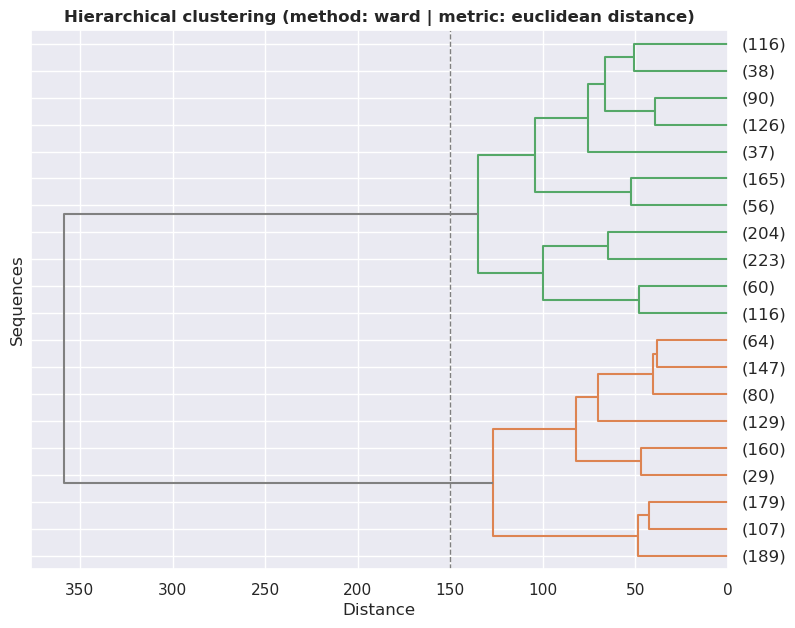

In [52]:
plt.figure(figsize=(9, 7))
dendrogram(
    hierarc_z,
    leaf_rotation=0, orientation="left",
    color_threshold=150, above_threshold_color='grey',
    truncate_mode='lastp', p=20,
)
plt.axvline(x=150, c='grey', lw=1, linestyle='dashed')

plt.title(
    'Hierarchical clustering (method: ward | metric: euclidean distance)',
    fontdict={ 'fontsize': 12, 'fontweight': 'bold' }
)
plt.xlabel('Distance', fontdict={ 'fontsize': 12 })
plt.ylabel('Sequences', fontdict={ 'fontsize': 12 })
plt.show()

Viral × EVE classes clustering view _(Long lines represent viral | Short lines represent EVEs)_

    In this view, clusters clearly separate the classes of the problem (this is evidence of the quality of our representations)

<Figure size 900x600 with 0 Axes>

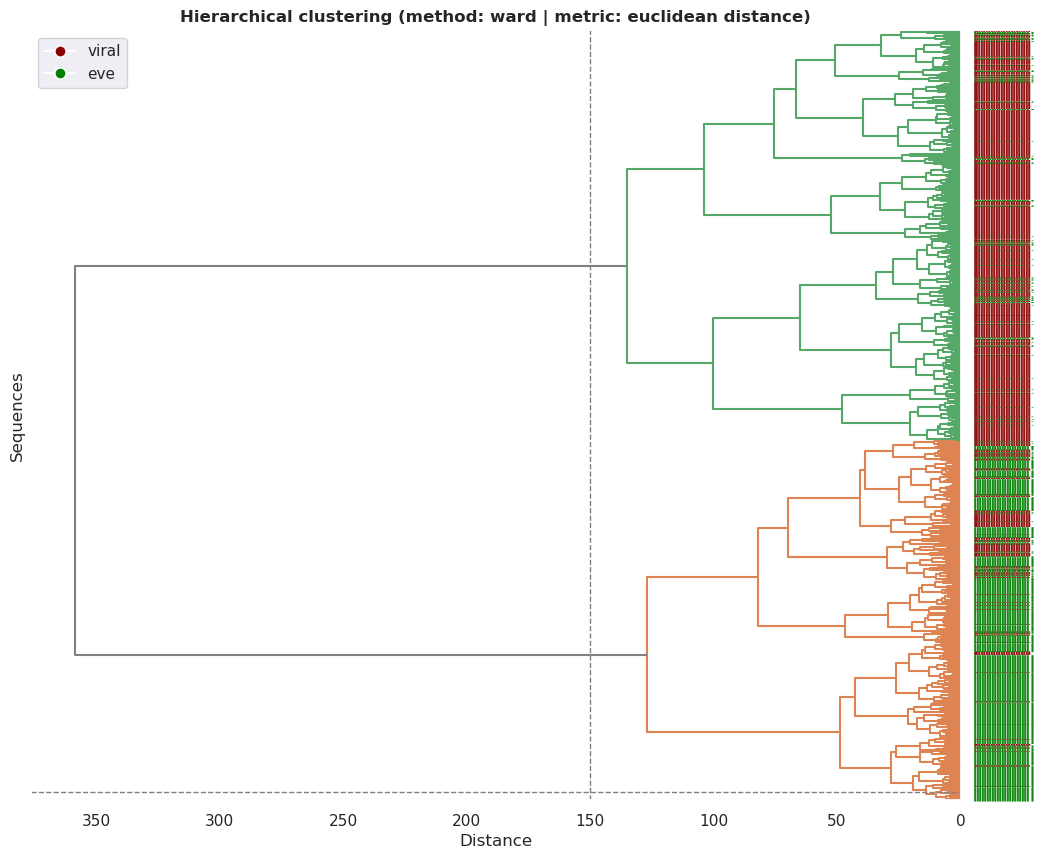

In [53]:
plt.clf()
plt.figure(figsize=(12, 10))

# Create dendogram
hierarc_label_viral = '-----------------------'
hierarc_label_eve = '---------------------- -'
hierarc_labels = y.replace([label_viral, label_eve], [hierarc_label_viral, hierarc_label_eve])

dendrogram(
    Z=hierarc_z, labels=hierarc_labels.values,
    leaf_rotation=0, orientation="left",
    color_threshold=150, above_threshold_color='grey',
)

# Show threshold lines
plt.axvline(x=150, c='grey', lw=1, linestyle='dashed')
plt.axhline(y=240, c='grey', lw=1, linestyle='dashed')

# Custom color mapping for labels
ax = plt.gca()
leaf_labels = ax.get_ymajorticklabels()

for l in leaf_labels:
    aux = label_viral if l.get_text() == hierarc_label_viral else label_eve
    l.set_color(label_color_map[aux])

# Custom color legend
label_patch = lambda label, color: plt.Line2D([0], [0], marker='o', color='w', label=label, markersize=8, markerfacecolor=color)
label_patches = [label_patch(label, color) for label, color in label_color_map.items()]
# plt.legend(handles=label_patches, title='Classes')
plt.legend(handles=label_patches, loc='upper left')

plt.title(
    'Hierarchical clustering (method: ward | metric: euclidean distance)',
    fontdict={ 'fontsize': 12, 'fontweight': 'bold' }
)

plt.xlabel('Distance', fontdict={ 'fontsize': 12 }) # REVIEW: 2023-10-06 - Is this axis label correct?
plt.ylabel('Sequences', fontdict={ 'fontsize': 12 })

plt.show()


#### Agglomerative clustering

Here we use the 2-D PCA components to segment the dataset with a few different number of clusters.
The quality of each clustering attempt is measured by silhouette scores

    It's clear that the best segmentation is achieved with two clusters. Which is evidence of the quality of our representations (the dataset is really made of two classes!)

In [54]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [55]:
n_clusters_list = [2, 3, 4, 5]
clusters_per_row = 4
silhouette_scores = []

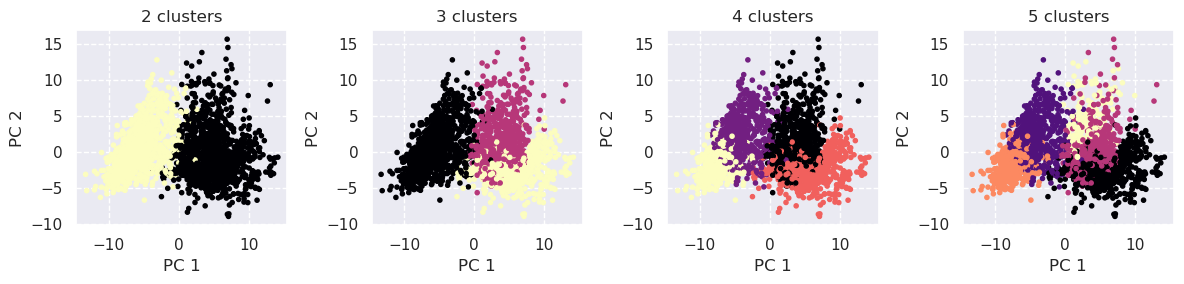

In [56]:
# Define number of rows / columns
n_rows = math.ceil(len(n_clusters_list) / clusters_per_row)
n_cols = clusters_per_row

# Create a grid of subplots
unit_height = 3
unit_width = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * unit_width, n_rows * unit_height))

# Plot histograms for each column
axes = axes.flatten()
for i in range(len(n_clusters_list)):
    
    ax = axes[i]
    n_clusters = n_clusters_list[i]

    ac = AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")
    ac_clusters = ac.fit_predict(X)
    
    silhouette_scores.append( silhouette_score(X, ac_clusters) )
    ax.scatter(pca2_proj[:, 0], pca2_proj[:, 1], c=ac.fit_predict(X), marker='.', cmap='magma')
    
    ax.set_title(f'{n_clusters} clusters', fontdict={ 'fontsize': 12 })
    ax.set_xlabel('PC 1')
    ax.set_ylabel('PC 2')
    ax.grid(linestyle="--")

plt.tight_layout()
plt.show()

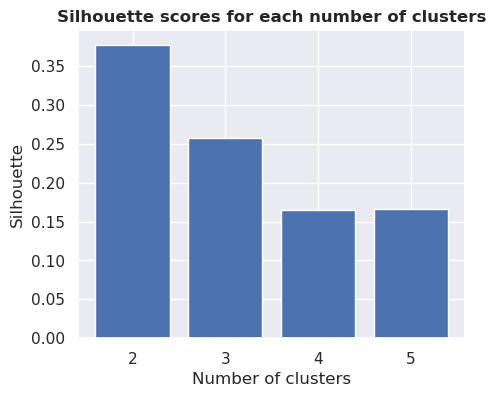

In [57]:
plt.figure(figsize=(5, 4))
plt.bar(n_clusters_list, silhouette_scores)
plt.xlabel('Number of clusters', fontsize=12)
plt.ylabel('Silhouette', fontsize=12)
plt.title('Silhouette scores for each number of clusters', fontdict={ 'fontweight': 'bold' })
plt.show()

#### K-Means

Here we use the K-Means algorithm as another mean to evaluate the quality of our representations.

In the next cells we can see that the best `k` value suggests the existence of 3 groups in our data. It could be evidence that our representations aren't quite good, but if we check the positions of the centroids it is clear that they are not placed in different regions _(they are too close)_ not even when we use `k`= 2.

Perhaps we could tune K-Means parameters better or further investigate why this algorithm doesn't seem to group our points well.

    But the fact that the position of the centroids doesn't seem to make sense independently of the value of k makes we consider that the inconsistency between how many clusters this analysis indicate our data has and how many classes it actually has, not to be a reason to doubt the quality of the representations.

In [58]:
import seaborn as sns
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer
from collections import Counter

In [59]:
k_range = (1, 10)

k_means_config = {
        'init': "k-means++", # Not random initialization of k-means centroids
        'n_init': 10,
        'max_iter': 300,
        'random_state': random_state,
}

In [60]:
def plot_distortion_score_elbow(data: pd.DataFrame, title: str) -> None:
    plt.figure(figsize=(8, 5))
    plt.clf()
    k_means = KMeans(**k_means_config)
    visualizer = KElbowVisualizer(k_means, k=k_range, title=title).fit(data)
    visualizer.show()

def plot_k_means(k_means: KMeans, pca_data: pd.DataFrame, title: str, n_clusters: int) -> None:
    
    plt.clf()
    plt.figure(figsize=(8, 5))
    
    palette = ['blue', 'gray', 'green', 'black'][:n_clusters]
    sns.scatterplot(data=pca_data, x="PC 1", y="PC 2", hue=k_means.labels_, palette=palette)
    
    plt.scatter(k_means.cluster_centers_[:, 0], k_means.cluster_centers_[:, 1], marker="X", c="r", s=80, label="Centroids")
    plt.legend(scatterpoints=1)
    plt.title(title)
    plt.tight_layout()
    plt.show()

Before using K-Means clustering we plot the SSE curve _(Sum of Squared Euclidean distances)_ to find the optimal `k` value _(number of clusters)_.

The curve's elbow is where the best trade-off between the `k` value and its score is.

Inspecting k-means using all features

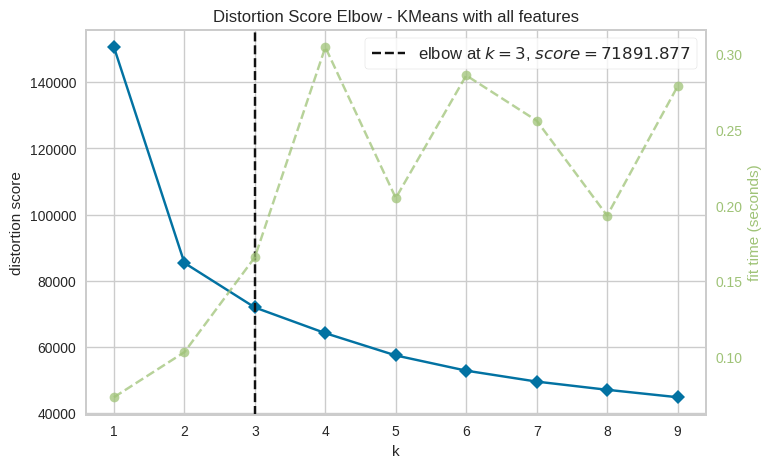

In [61]:
plot_distortion_score_elbow(data=X, title='Distortion Score Elbow - KMeans with all features')

Inspecting k-means using PCA 3 principal components

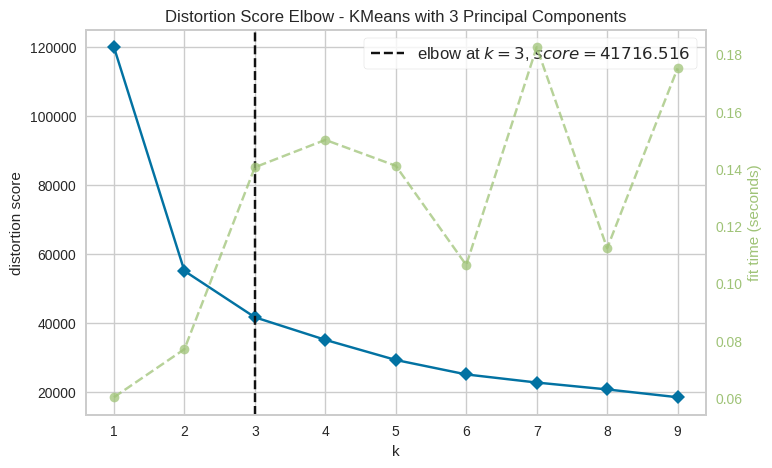

In [62]:
plot_distortion_score_elbow(data=pca3_proj, title='Distortion Score Elbow - KMeans with 3 Principal Components')

Show k-means clustering using 2 clusters as we know that our dataset has two classes _(using PCA 2 principal components for 2D visualization)_ 

Classifications per cluster: Counter({1: 1241, 0: 1074})


<Figure size 800x550 with 0 Axes>

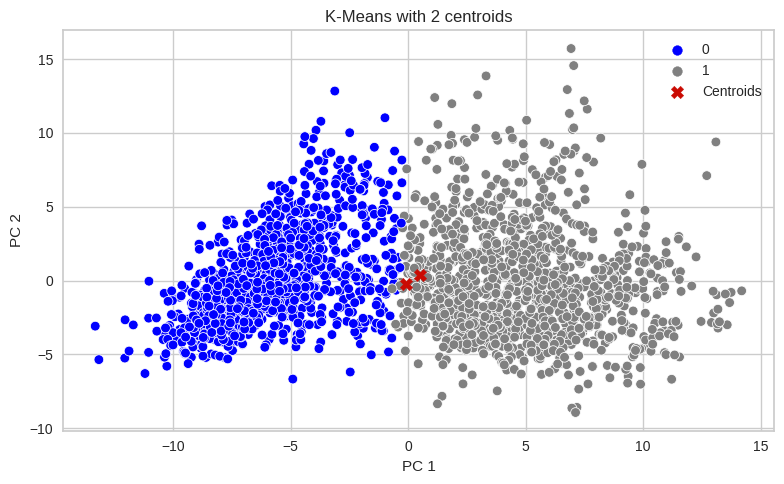

In [63]:
k_means2 = KMeans(n_clusters=2, **k_means_config).fit(X)
print(f'Classifications per cluster: {Counter(k_means2.labels_)}')
plot_k_means(k_means=k_means2, pca_data=pca2_aux_df, title='K-Means with 2 centroids', n_clusters=2)

Show k-means clustering using 3 clusters as indicated by the both distortion score elbow analysis _(using PCA 2 principal components for 2D visualization)_ 

Classifications per cluster: Counter({0: 958, 2: 865, 1: 492})


<Figure size 800x550 with 0 Axes>

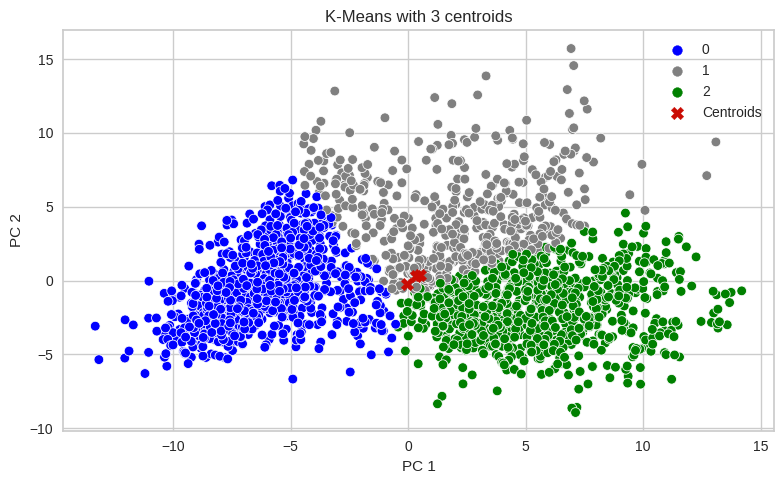

In [64]:
k_means3 = KMeans(n_clusters=3, **k_means_config).fit(X)
print(f'Classifications per cluster: {Counter(k_means3.labels_)}')
plot_k_means(k_means=k_means3, pca_data=pca2_aux_df, title='K-Means with 3 centroids', n_clusters=3)

Show k-means clustering using 4 clusters just to check if we get anything different _(using PCA 2 principal components for 2D visualization)_ 

Classifications per cluster: Counter({1: 940, 3: 645, 2: 367, 0: 363})


<Figure size 800x550 with 0 Axes>

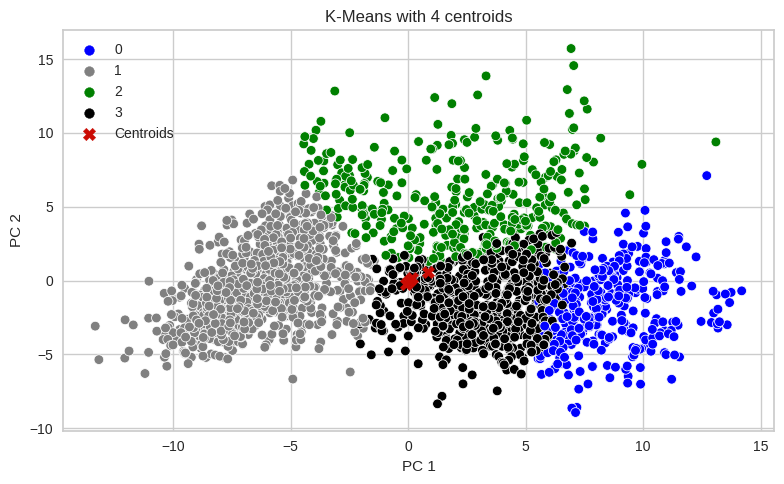

In [65]:
k_means4 = KMeans(n_clusters=4, **k_means_config).fit(X)
print(f'Classifications per cluster: {Counter(k_means4.labels_)}')
plot_k_means(k_means=k_means4, pca_data=pca2_aux_df, title='K-Means with 4 centroids', n_clusters=4)

## Model Selection

In [72]:
''' 
    # TODO: 2023-10-10 - ADD Description
    # TODO: 2023-10-10 - Try other search methods (e.g. random, baysian, etc.)
''' 


# **Normalização dos dados**
# A matriz de atributos utilizada nesse trabalho é saída de uma ferramenta que estou construindo no meu doutorado "Small RNA Metavir" (https://github.com/JPbio/small_RNA_MetaVir) para processar dads de RNA-seq em larga escala e "mineirar" sequências virais. As features já sairam do pipeline de mineiração "normalizadas" com calculos que levam em conta peculiaridades das bibliotecas de RNA-seq (dado bruto) e utiliza "Z-score" ao final, tudo aplicado com scripts escritos em R. Portanto, não será necessário realizar normalizações para aplicaões de modelos de aprendizado nesse notebook.

' \n    # TODO: 2023-10-10 - ADD Description\n'

In [16]:
# #Bibliotecas para tratamento dos dados e visualizações gerais
# import io
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

# #Bibliotecas de uso geral para os experimentos
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import StandardScaler
# from sklearn.compose import ColumnTransformer

# from sklearn.preprocessing import MinMaxScaler
# from sklearn.decomposition import PCA
# from sklearn.model_selection import cross_val_score
# from sklearn.metrics import (
#     ConfusionMatrixDisplay,
#     accuracy_score,
#     recall_score,
#     precision_score,
#     confusion_matrix,
#     roc_auc_score,
#     roc_curve
#     )
# from sklearn.metrics import RocCurveDisplay, DetCurveDisplay

# #Bibliotecas para avaliação e seleção dos modelos
# from sklearn.model_selection import GridSearchCV

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

Split data for training / testing

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=random_state, stratify=y)

print(f'X_train.shape: {X_train.shape}\t X_test.shape: {X_test.shape}')
print(f'y_train.shape: {y_train.shape}\t\t y_test.shape: {y_test.shape}')


X_train.shape: (1620, 48)	 X_test.shape: (695, 48)
y_train.shape: (1620,)		 y_test.shape: (695,)


### Naive Bayes

This is a very simple model, so its performance might be used as a baseline to evaluate the performance of other more complex ones

In [69]:
from sklearn.naive_bayes import GaussianNB

In [120]:

nbayes_pipe = Pipeline( steps=[("clf", GaussianNB())])

nbayes_grid_params = { 'clf__var_smoothing': np.logspace(0, -9, num=100) }

nbayes_grid = GridSearchCV(
    estimator=nbayes_pipe,
    param_grid=nbayes_grid_params,
    scoring='accuracy',
    cv=5,
    return_train_score=True,
)


In [87]:
nbayes_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Pipeline(steps=[('clf', GaussianNB())]),
             param_grid={'clf__var_smoothing': array([1.00000000e+00, 8.11130831e-01, 6.57933225e-01, 5.33669923e-01,
       4.32876128e-01, 3.51119173e-01, 2.84803587e-01, 2.31012970e-01,
       1.87381742e-01, 1.51991108e-01, 1.23284674e-01, 1.00000000e-01,
       8.11130831e-02, 6.57933225e-02, 5.33669923e-02, 4.32876128e-02,
       3.5...
       1.23284674e-07, 1.00000000e-07, 8.11130831e-08, 6.57933225e-08,
       5.33669923e-08, 4.32876128e-08, 3.51119173e-08, 2.84803587e-08,
       2.31012970e-08, 1.87381742e-08, 1.51991108e-08, 1.23284674e-08,
       1.00000000e-08, 8.11130831e-09, 6.57933225e-09, 5.33669923e-09,
       4.32876128e-09, 3.51119173e-09, 2.84803587e-09, 2.31012970e-09,
       1.87381742e-09, 1.51991108e-09, 1.23284674e-09, 1.00000000e-09])},
             return_train_score=True, scoring='accuracy')

In [89]:
nbayes_grid_table_df = pd.DataFrame(nbayes_grid.cv_results_)
nbayes_grid_table_df.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__var_smoothing,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.006151,0.001603,0.002835,0.000304,1.0,{'clf__var_smoothing': 1.0},0.895062,0.870370,0.861111,0.919753,...,0.877778,0.026949,60,0.875772,0.881173,0.884259,0.871142,0.888117,0.880093,0.006028
1,0.006069,0.002230,0.002900,0.000434,0.811131,{'clf__var_smoothing': 0.8111308307896871},0.891975,0.870370,0.861111,0.919753,...,0.877160,0.026579,63,0.874228,0.879630,0.884259,0.870370,0.885802,0.878858,0.005856
2,0.004376,0.001075,0.002393,0.000235,0.657933,{'clf__var_smoothing': 0.657933224657568},0.891975,0.873457,0.858025,0.922840,...,0.877778,0.027853,62,0.873457,0.878858,0.881944,0.869599,0.885802,0.877932,0.005803
3,0.003921,0.000956,0.002579,0.000764,0.53367,{'clf__var_smoothing': 0.533669923120631},0.888889,0.870370,0.858025,0.919753,...,0.875926,0.026651,67,0.873457,0.876543,0.881944,0.867284,0.884259,0.876698,0.006064
4,0.004460,0.001094,0.002285,0.000365,0.432876,{'clf__var_smoothing': 0.43287612810830584},0.888889,0.873457,0.858025,0.919753,...,0.875926,0.027356,67,0.873457,0.875772,0.881944,0.865741,0.885031,0.876389,0.006751


Evaluate classification with the best model

In [109]:
print(f"Best smoothing value: {nbayes_grid.best_params_} with {format_percent(nbayes_grid.best_score_)} of accuracy")

Best smoothing value: {'clf__var_smoothing': 8.111308307896873e-06} with 88.33% of accuracy


In [100]:
nbayes_grid_predictions = nbayes_grid.predict(X_test)
print('Performance metrics')
print(classification_report(y_test, nbayes_grid_predictions))

Performance metrics
              precision    recall  f1-score   support

         eve       0.88      0.88      0.88       298
       viral       0.91      0.91      0.91       397

    accuracy                           0.90       695
   macro avg       0.89      0.89      0.89       695
weighted avg       0.90      0.90      0.90       695



### Decision Tree

This is another very simple approach which is also very explainable. This is good to have a picture of our features importance.

    The analysis along the next cells show that the most important feature is the X.21 (21 nucleotides in the antisense strand). This is expected as could be seen in the feature values distribution plots.

In [54]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [55]:
dtree_pipe = Pipeline(
    steps=[("clf", DecisionTreeClassifier(random_state=random_state))]
)

dtree_grid_params = { 'clf__max_depth': np.arange(start=3, stop=100, step=3) }
dtree_grid = GridSearchCV(
    estimator=dtree_pipe,
    param_grid=dtree_grid_params,
    cv=5,
    scoring='accuracy',
    return_train_score=True,
)


In [56]:
dtree_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('clf',
                                        DecisionTreeClassifier(random_state=123))]),
             param_grid={'clf__max_depth': array([ 3,  6,  9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48, 51,
       54, 57, 60, 63, 66, 69, 72, 75, 78, 81, 84, 87, 90, 93, 96, 99])},
             return_train_score=True, scoring='accuracy')

In [57]:
dtree_grid_table = pd.DataFrame(dtree_grid.cv_results_)
dtree_grid_table.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.025916,0.006587,0.002545,0.000422,3,{'clf__max_depth': 3},0.922840,0.901235,0.870370,0.913580,...,0.896296,0.021078,2,0.924383,0.933642,0.932870,0.922840,0.930556,0.928858,0.004430
1,0.037969,0.001506,0.002087,0.000143,6,{'clf__max_depth': 6},0.916667,0.898148,0.873457,0.941358,...,0.898765,0.028180,1,0.960648,0.969136,0.965278,0.959105,0.966049,0.964043,0.003671
2,0.048812,0.000980,0.002152,0.000274,9,{'clf__max_depth': 9},0.922840,0.891975,0.848765,0.925926,...,0.891358,0.030266,3,0.976852,0.982253,0.983796,0.979167,0.978395,0.980093,0.002554
3,0.062273,0.000773,0.002326,0.000265,12,{'clf__max_depth': 12},0.929012,0.873457,0.854938,0.907407,...,0.888272,0.026435,4,0.991512,0.993827,0.993827,0.996914,0.996914,0.994599,0.002070
4,0.079490,0.010886,0.004213,0.002402,15,{'clf__max_depth': 15},0.922840,0.867284,0.848765,0.895062,...,0.880864,0.025645,5,0.997685,1.000000,1.000000,1.000000,1.000000,0.999537,0.000926


Evaluate how estimated error varies depending on decision trees depth

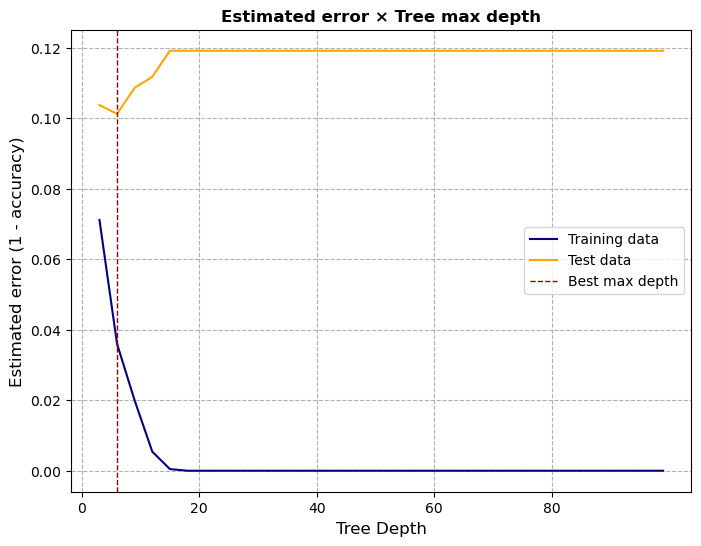

In [58]:
plt.figure(figsize=(8, 6))

plt.plot(
    dtree_grid.cv_results_['param_clf__max_depth'], 1 - dtree_grid.cv_results_['mean_train_score'],
    color='navy', label="Training data",
)
plt.plot(
    dtree_grid.cv_results_['param_clf__max_depth'], 1 - dtree_grid.cv_results_['mean_test_score'],
    color='orange',label="Test data"
)

plt.axvline(x=dtree_grid.best_params_['clf__max_depth'], c='darkred', lw=1, linestyle='dashed', label='Best max depth')

plt.xlabel('Tree Depth', fontdict={ 'fontsize': 12 })
plt.ylabel('Estimated error (1 - accuracy)', fontdict={ 'fontsize': 12 })
plt.legend(loc='best')

plt.xticks(range(0, 100, 20),)
plt.grid(linestyle="--")

plt.title('Estimated error × Tree max depth', fontdict={ 'fontweight': 'bold' })
plt.show()

Evaluate classification with best model

In [59]:
print(f"Best value: {dtree_grid.best_params_} with {format_percent(dtree_grid.best_score_)} of accuracy")

Best value: {'clf__max_depth': 6} with 89.88% of accuracy


In [60]:
dtree_grid_predictions = dtree_grid.predict(X_test)
print('Performance metrics')
print(classification_report(y_test, dtree_grid_predictions))

Performance metrics
              precision    recall  f1-score   support

         eve       0.92      0.89      0.90       298
       viral       0.92      0.94      0.93       397

    accuracy                           0.92       695
   macro avg       0.92      0.92      0.92       695
weighted avg       0.92      0.92      0.92       695



Evaluate the model with best performance

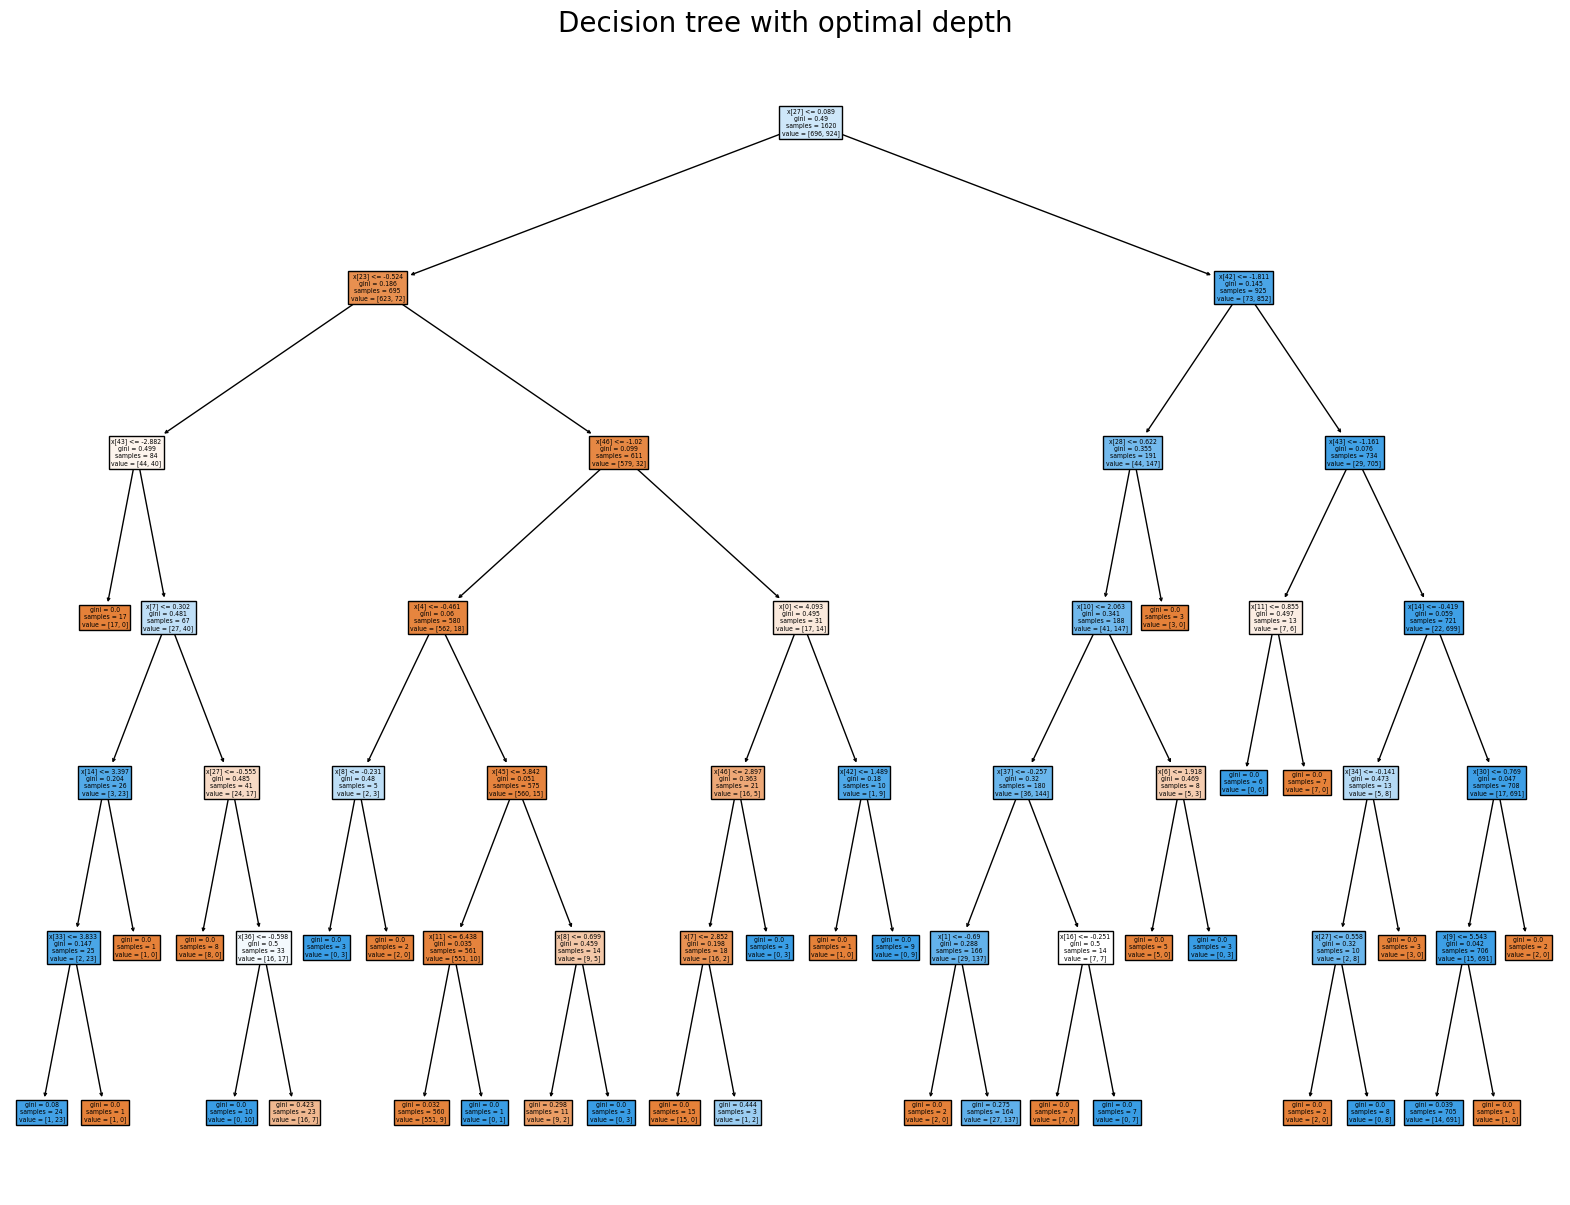

In [61]:
plt.figure(figsize=(20, 15))
plot_tree(dtree_grid.best_estimator_["clf"], filled=True)
plt.title("Decision tree with optimal depth", fontdict={ 'fontsize': 20 })
plt.show()

Checking the feature with highest gain of information (the one that splits the tree at the first node).

We see it's `X.21` which represents the quantity of 21 nucleotides length RNA in the antisense strand. This makes totally sense as this is a high relevance biochemical molecule for viral infections.

In [62]:
print(f'Feature that splits the tree at the first node: "{X.columns[27]}"')

Feature that splits the tree at the first node: "X.21"


### SVM _(Support Vector Machine)_

''' 
    # TODO: 2023-10-10 - ADD Description
''' 

In [47]:
from sklearn.svm import SVC

In [48]:
svm_pipe = Pipeline(
    steps=[ ("clf", SVC(random_state=random_state)) ]
)

svm_grid_params = {
    'clf__kernel': ["poly", "linear", "rbf", "sigmoid"],
    'clf__degree' : [2, 3, 4, 5, 6],
}

svm_grid = GridSearchCV(
    estimator=svm_pipe,
    param_grid=svm_grid_params,
    cv=5,
    scoring='accuracy',
    return_train_score=True,
)

In [49]:
svm_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Pipeline(steps=[('clf', SVC(random_state=123))]),
             param_grid={'clf__degree': [2, 3, 4, 5, 6],
                         'clf__kernel': ['poly', 'linear', 'rbf', 'sigmoid']},
             return_train_score=True, scoring='accuracy')

In [50]:
svm_grid_table = pd.DataFrame(svm_grid.cv_results_)
svm_grid_table.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__degree,param_clf__kernel,params,split0_test_score,split1_test_score,split2_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.035024,0.002858,0.006690,0.000310,2,poly,"{'clf__degree': 2, 'clf__kernel': 'poly'}",0.935185,0.898148,0.898148,...,0.913580,0.026479,6,0.920525,0.921296,0.928241,0.912809,0.926698,0.921914,0.005443
1,0.077670,0.005561,0.004627,0.000419,2,linear,"{'clf__degree': 2, 'clf__kernel': 'linear'}",0.922840,0.891975,0.882716,...,0.904938,0.024645,8,0.918981,0.921296,0.925926,0.912809,0.925154,0.920833,0.004746
2,0.032189,0.002209,0.009913,0.000894,2,rbf,"{'clf__degree': 2, 'clf__kernel': 'rbf'}",0.932099,0.901235,0.901235,...,0.914815,0.024583,1,0.921296,0.932870,0.932870,0.922840,0.930556,0.928086,0.005010
3,0.071793,0.017186,0.013769,0.003419,2,sigmoid,"{'clf__degree': 2, 'clf__kernel': 'sigmoid'}",0.839506,0.827160,0.842593,...,0.838889,0.022291,16,0.821759,0.838735,0.851852,0.824846,0.835648,0.834568,0.010732
4,0.050720,0.009199,0.009781,0.001915,3,poly,"{'clf__degree': 3, 'clf__kernel': 'poly'}",0.932099,0.888889,0.888889,...,0.906790,0.023294,7,0.919753,0.925926,0.931327,0.919753,0.929784,0.925309,0.004865


Evaluate classification with the best model

In [52]:
print(f"Best value: {svm_grid.best_params_} with {format_percent(svm_grid.best_score_)} of accuracy")

Best value: {'clf__degree': 2, 'clf__kernel': 'rbf'} with 91.48% of accuracy


In [53]:
svm_grid_predictions = svm_grid.predict(X_test)
print('Performance metrics')
print(classification_report(y_test, svm_grid_predictions))

Performance metrics
              precision    recall  f1-score   support

         eve       0.93      0.90      0.92       298
       viral       0.93      0.95      0.94       397

    accuracy                           0.93       695
   macro avg       0.93      0.93      0.93       695
weighted avg       0.93      0.93      0.93       695



### KNN _(K Nearest neighbors)_

''' 
    # TODO: 2023-10-10 - ADD Description
''' 

In [42]:
from sklearn.neighbors import KNeighborsClassifier

In [44]:
knn_pipe = Pipeline(
    steps=[ ("clf", KNeighborsClassifier()) ]
)

knn_grid_params = { 'clf__n_neighbors' : np.arange(start=3, stop=100, step=3) }

knn_grid = GridSearchCV(
    estimator=knn_pipe,
    param_grid=knn_grid_params,
    cv=5,
    scoring='accuracy',
    return_train_score=True,
)


In [31]:
knn_grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=Pipeline(steps=[('clf', KNeighborsClassifier())]),
             param_grid={'clf__n_neighbors': array([ 3,  6,  9, 12, 15, 18, 21, 24, 27, 30, 33, 36, 39, 42, 45, 48, 51,
       54, 57, 60, 63, 66, 69, 72, 75, 78, 81, 84, 87, 90, 93, 96, 99])},
             return_train_score=True, scoring='accuracy')

In [32]:
knn_grid_table = pd.DataFrame(knn_grid.cv_results_)
knn_grid_table.head()


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.006029,0.004056,0.040820,0.016822,3,{'clf__n_neighbors': 3},0.913580,0.885802,0.891975,0.938272,...,0.906790,0.018457,5,0.947531,0.949846,0.953704,0.948302,0.949846,0.949846,0.002127
1,0.004180,0.000584,0.030123,0.005259,6,{'clf__n_neighbors': 6},0.935185,0.910494,0.879630,0.944444,...,0.909259,0.027785,4,0.926698,0.930556,0.932099,0.922068,0.932099,0.928704,0.003861
2,0.003794,0.000133,0.035000,0.007758,9,{'clf__n_neighbors': 9},0.935185,0.904321,0.888889,0.947531,...,0.912963,0.024177,1,0.922068,0.927469,0.925926,0.913580,0.929784,0.923765,0.005679
3,0.003877,0.000302,0.036960,0.009181,12,{'clf__n_neighbors': 12},0.935185,0.904321,0.891975,0.950617,...,0.912346,0.026593,2,0.912809,0.923611,0.923611,0.908951,0.921296,0.918056,0.006044
4,0.004192,0.000682,0.049829,0.024237,15,{'clf__n_neighbors': 15},0.929012,0.907407,0.898148,0.947531,...,0.911111,0.025481,3,0.908951,0.919753,0.921296,0.908951,0.918981,0.915586,0.005469


Evaluate how estimated error varies depending on `k` value _(number of neighbors)_

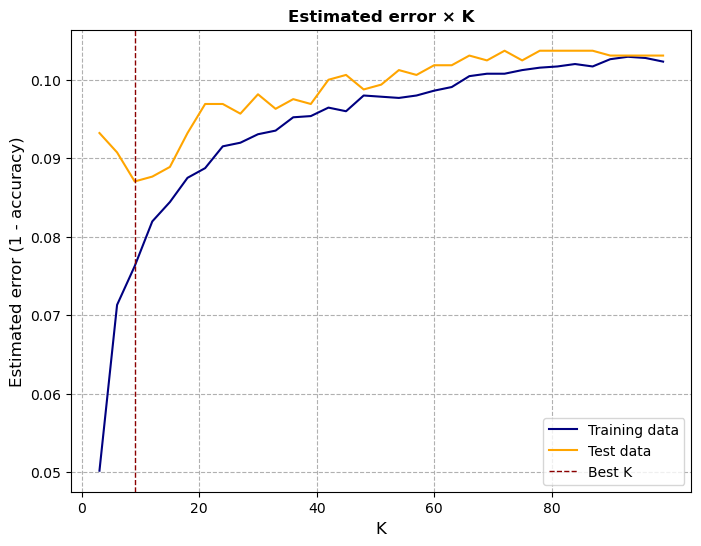

In [36]:
plt.figure(figsize=(8, 6))

plt.plot(
    knn_grid.cv_results_['param_clf__n_neighbors'], 1 - knn_grid.cv_results_['mean_train_score'],
    color='navy', label="Training data"
)
plt.plot(
    knn_grid.cv_results_['param_clf__n_neighbors'], 1 - knn_grid.cv_results_['mean_test_score'],
    color='orange',label="Test data"
)

plt.axvline(x=knn_grid.best_params_['clf__n_neighbors'], c='darkred', lw=1, linestyle='dashed', label='Best K')

plt.xlabel('K', fontdict={ 'fontsize': 12 })
plt.ylabel('Estimated error (1 - accuracy)', fontdict={ 'fontsize': 12 })
plt.legend(loc='best')

plt.xticks(range(0, 100, 20),)
plt.grid(linestyle="--")

plt.title('Estimated error × K', fontdict={ 'fontweight': 'bold' })
plt.show()

Evaluate performance of the best model

In [34]:
print(f"Best value of K: {knn_grid.best_params_} with {format_percent(knn_grid.best_score_)} of accuracy")

Best value of K: {'clf__n_neighbors': 9} with 91.30% of accuracy


In [43]:
knn_grid_predictions = knn_grid.predict(X_test)
print('Performance metrics')
print(classification_report(y_test, knn_grid_predictions))

Performance metrics
              precision    recall  f1-score   support

         eve       0.94      0.90      0.92       298
       viral       0.93      0.96      0.94       397

    accuracy                           0.93       695
   macro avg       0.93      0.93      0.93       695
weighted avg       0.93      0.93      0.93       695



### Ensemble

In [ ]:
''' 
    # TODO: 2023-10-10 - ADD Description
'''

<!-- Foi discutido nessa disciplina que o "estado da arte" do aprendizado supervisionado para lidar com problemas de classificação com dados estruturas são os modelos ensamble. No caso do meu problema, eles são ainda mais relevantes, por que eu tenho poucos dados, es estou em uma área perigosa de risco de "overfitting", o que pode ser até certo ponto, combatido com bagging (lida com erro de variância) e boosting (lida com erro de viés).

Em algum momento, eu poderia cogitar alguma abordam de NLP, já que tenho minhas sequências de RNAs montadas, porém, nas minhas estimativas mais otimistas de recursos financeiros e poder de mineiração de dados publicos que tenho até o final do doutorado, dificilmente conseguirei mais de 3 mil exemplos para cada uma de minhas classes eves e viral. Por isso, meu enfoque nos ensembles para meu problema. -->

#### Random Forest

''' 
    # TODO: 2023-10-10 - ADD Description
''' 

In [1]:
from sklearn.ensemble import RandomForestClassifier

In [37]:
rf_pipe = Pipeline(
    steps=[("clf", RandomForestClassifier(random_state=random_state))]
)

rf_grid_params = {
    'clf__n_estimators': np.arange(start=50, stop=500, step=50),
}
rf_grid = GridSearchCV(
    estimator=rf_pipe,
    param_grid=rf_grid_params,
    cv=5,
    scoring='accuracy',
    return_train_score=True,
)

In [38]:
rf_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('clf',
                                        RandomForestClassifier(random_state=123))]),
             param_grid={'clf__n_estimators': array([ 50, 100, 150, 200, 250, 300, 350, 400, 450])},
             return_train_score=True, scoring='accuracy')

In [39]:
rf_grid_table = pd.DataFrame(rf_grid.cv_results_)
rf_grid_table.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_clf__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,...,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,split3_train_score,split4_train_score,mean_train_score,std_train_score
0,0.383407,0.043319,0.010638,0.002736,50,{'clf__n_estimators': 50},0.941358,0.916667,0.907407,0.941358,...,0.921605,0.016860,5,0.999228,0.999228,1.0,1.0,1.0,0.999691,0.000378
1,0.678214,0.019347,0.016235,0.001321,100,{'clf__n_estimators': 100},0.935185,0.910494,0.901235,0.941358,...,0.918519,0.016517,9,1.000000,1.000000,1.0,1.0,1.0,1.000000,0.000000
2,0.993077,0.124486,0.024210,0.003773,150,{'clf__n_estimators': 150},0.935185,0.904321,0.910494,0.947531,...,0.920988,0.017196,8,1.000000,1.000000,1.0,1.0,1.0,1.000000,0.000000
3,1.319024,0.068178,0.033765,0.008110,200,{'clf__n_estimators': 200},0.941358,0.901235,0.910494,0.950617,...,0.921605,0.020342,5,1.000000,1.000000,1.0,1.0,1.0,1.000000,0.000000
4,1.787605,0.233128,0.044618,0.009244,250,{'clf__n_estimators': 250},0.941358,0.901235,0.910494,0.953704,...,0.921605,0.021789,5,1.000000,1.000000,1.0,1.0,1.0,1.000000,0.000000


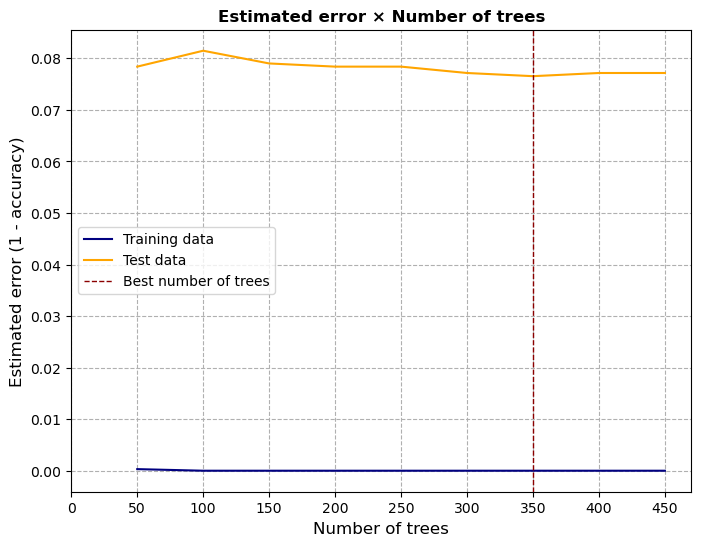

In [40]:
plt.figure(figsize=(8, 6))

plt.plot(
    rf_grid.cv_results_['param_clf__n_estimators'], 1 - rf_grid.cv_results_['mean_train_score'],
    color='navy', label="Training data"
)
plt.plot(
    rf_grid.cv_results_['param_clf__n_estimators'], 1 - rf_grid.cv_results_['mean_test_score'],
    color='orange',label="Test data"
)

plt.axvline(x=rf_grid.best_params_['clf__n_estimators'], c='darkred', lw=1, linestyle='dashed', label='Best number of trees')

plt.xlabel('Number of trees', fontdict={ 'fontsize': 12 })
plt.ylabel('Estimated error (1 - accuracy)', fontdict={ 'fontsize': 12 })
plt.legend(loc='best')

plt.xticks(range(0, 500, 50),)
plt.grid(linestyle="--")

plt.title('Estimated error × Number of trees', fontdict={ 'fontweight': 'bold' })
plt.show()

Evaluate the performance of the best model

In [41]:
print(f"Best number of trees: {rf_grid.best_params_} with {format_percent(rf_grid.best_score_)} of accuracy")

Best number of trees: {'clf__n_estimators': 350} with 92.35% of accuracy


In [45]:
rf_grid_predictions = rf_grid.predict(X_test)
print('Performance metrics')
print(classification_report(y_test, rf_grid_predictions))

Performance metrics
              precision    recall  f1-score   support

         eve       0.95      0.90      0.92       298
       viral       0.93      0.96      0.95       397

    accuracy                           0.94       695
   macro avg       0.94      0.93      0.93       695
weighted avg       0.94      0.94      0.94       695



#### Adaboost _(Adaptive Boosting)_

#### Gradient Tree Boosting

#### CAT Boost ????

#### XG Boost

#### Light GBM